# Task 1 Exploratory Data Analysis

In [1]:
 # %% Imports
import matplotlib.pyplot as plt
from IPython.display import display
import importlib
import utils
from utils import DataLoader
# Reload the latest version of utils.py
importlib.reload(utils)
import pandas as pd
import numpy as np

# %% Load data
loader = utils.DataLoader()
loader.load_dataset()
data = loader.data
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## Data Quality and Descriptive Results

In [2]:
# Rows and Columns
print("Rows and Columns: ", data.shape)


Rows and Columns:  (5110, 12)


In [3]:
# Duplicate records or IDs
print("\nNumber of duplicate IDs:", data["id"].duplicated().sum())


Number of duplicate IDs: 0


In [4]:
# Distribution for Missingness
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy for missingness analysis
eda_data = data.copy()

# Treat "Unknown" smoking status as an unknown/missing value
eda_data["smoking_status"] = eda_data["smoking_status"].replace("Unknown", pd.NA)

# Missingness summary
missing_summary = pd.DataFrame({
    "Missing Count": eda_data.isnull().sum(),
    "Missing Percentage (%)": (
        eda_data.isnull().sum() / len(eda_data) * 100
    ).round(2)
})

missing_summary

,Missing Count,Missing Percentage (%)
id,0,0.00
gender,0,0.00
age,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
ever_married,0,0.00
work_type,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00
bmi,201,3.93


In [5]:

# Stroke Class Count
stroke_counts = data["stroke"].value_counts().sort_index()
stroke_percentage = (data["stroke"].value_counts(normalize=True).sort_index() * 100).round(2)

stroke_summary = pd.DataFrame({
    "Count": stroke_counts,
    "Percentage (%)": stroke_percentage
})

print(stroke_summary)



        Count  Percentage (%)
stroke                       
0        4861           95.13
1         249            4.87


In [6]:
# Mean ± SD, Median (IQR), and Range (Min–Max)
variables = ["age", "avg_glucose_level", "bmi"]

summary = pd.DataFrame({
    "Mean ± SD": [
        f"{data[col].mean():.2f} ± {data[col].std():.2f}"
        for col in variables
    ],
    "Median (IQR)": [
        f"{data[col].median():.2f} ({data[col].quantile(0.25):.2f}–{data[col].quantile(0.75):.2f})"
        for col in variables
    ],
    "Range (Min–Max)": [
        f"{data[col].min():.2f}–{data[col].max():.2f}"
        for col in variables
    ]
}, index=variables)

print(summary)

                        Mean ± SD          Median (IQR) Range (Min–Max)
age                 43.23 ± 22.61   45.00 (25.00–61.00)      0.08–82.00
avg_glucose_level  106.15 ± 45.28  91.88 (77.25–114.09)    55.12–271.74
bmi                  28.89 ± 7.85   28.10 (23.50–33.10)     10.30–97.60


In [7]:
# Categorical distributions with counts and percentages
categorical_cols = data.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    print(f"\n{col}:")

    counts = data[col].value_counts(dropna=False)
    percentages = data[col].value_counts(normalize=True, dropna=False) * 100

    summary = pd.DataFrame({
        'Count': counts,
        'Percentage (%)': percentages.round(2)
    })

    print(summary)


gender:
        Count  Percentage (%)
gender                       
Female   2994           58.59
Male     2115           41.39
Other       1            0.02

ever_married:
              Count  Percentage (%)
ever_married                       
Yes            3353           65.62
No             1757           34.38

work_type:
               Count  Percentage (%)
work_type                           
Private         2925           57.24
Self-employed    819           16.03
children         687           13.44
Govt_job         657           12.86
Never_worked      22            0.43

Residence_type:
                Count  Percentage (%)
Residence_type                       
Urban            2596            50.8
Rural            2514            49.2

smoking_status:
                 Count  Percentage (%)
smoking_status                        
never smoked      1892           37.03
Unknown           1544           30.22
formerly smoked    885           17.32
smokes             789        

C:\Users\user\AppData\Local\Temp\ipykernel_2444\421258761.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = data.select_dtypes(include=['object', 'category']).columns


## Figure 1 EDA Panel

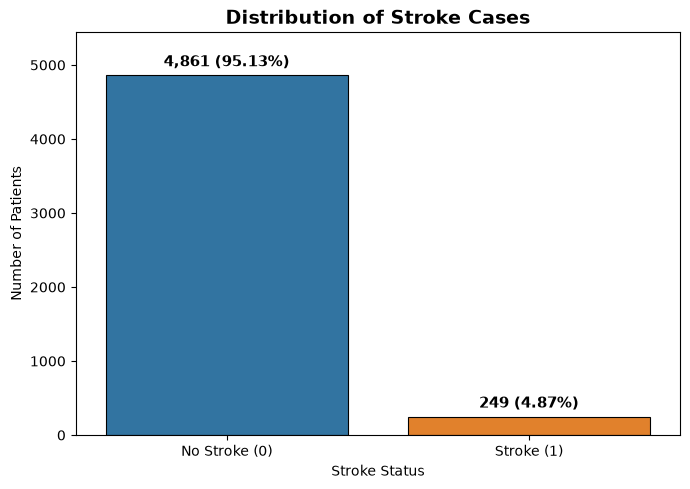

               Count  Percentage (%)
No Stroke (0)   4861           95.13
Stroke (1)       249            4.87


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Stroke distribution: Count and Percentage
stroke_counts = data['stroke'].value_counts().reindex([0, 1], fill_value=0)
stroke_percentages = stroke_counts / stroke_counts.sum() * 100

# Match colours from All Columns by Stroke
stroke_colors = {
    'No Stroke (0)': 'tab:blue',
    'Stroke (1)': 'tab:orange'
}

labels = ['No Stroke (0)', 'Stroke (1)']

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=labels,
    y=stroke_counts.values,
    hue=labels,
    palette=stroke_colors,
    legend=False,
    edgecolor='black',
    linewidth=0.8
)

# Add count and percentage labels
for i, (count, percentage) in enumerate(zip(stroke_counts, stroke_percentages)):
    ax.text(
        i, count + stroke_counts.max() * 0.015,
        f'{count:,} ({percentage:.2f}%)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.title('Distribution of Stroke Cases', fontsize=14, fontweight='bold')
plt.xlabel('Stroke Status')
plt.ylabel('Number of Patients')
plt.ylim(0, stroke_counts.max() * 1.12)
plt.tight_layout()
plt.show()

# Display summary table
stroke_summary = pd.DataFrame({
    'Count': stroke_counts,
    'Percentage (%)': stroke_percentages.round(2)
})

stroke_summary.index = labels
print(stroke_summary)

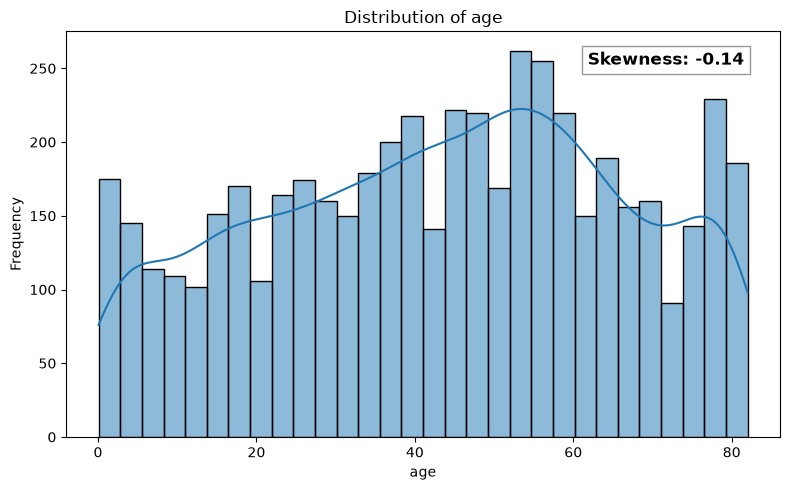

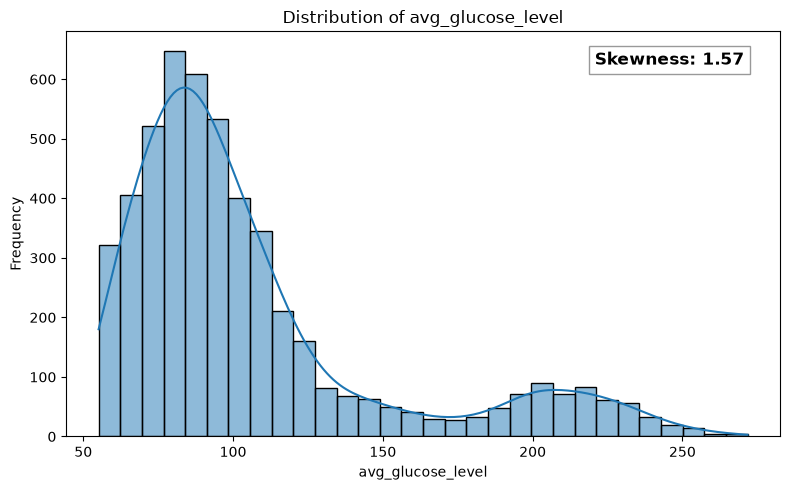

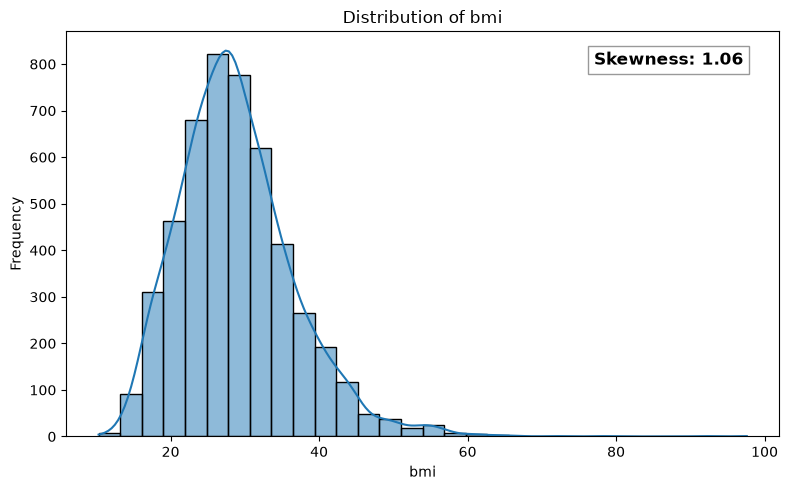

In [9]:
# Distribution of age, avg_glucose_level and bmi
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ["age", "avg_glucose_level", "bmi"]

for col in numerical_cols:
    plt.figure(figsize=(8, 5))

    sns.histplot(data[col].dropna(), bins=30, kde=True)

    # Calculate skewness
    skewness = data[col].skew()

    # Add skewness text inside the graph
    plt.text(
        0.95, 0.95,
        f"Skewness: {skewness:.2f}",
        transform=plt.gca().transAxes,
        fontsize=12,
        fontweight="bold",
        ha="right",
        va="top",
        bbox=dict(facecolor="white", edgecolor="gray", alpha=0.8)
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

               No Stroke  Stroke  Total  Stroke Rate (%)
BMI Available       4700     209   4909             4.26
BMI Missing          161      40    201            19.90


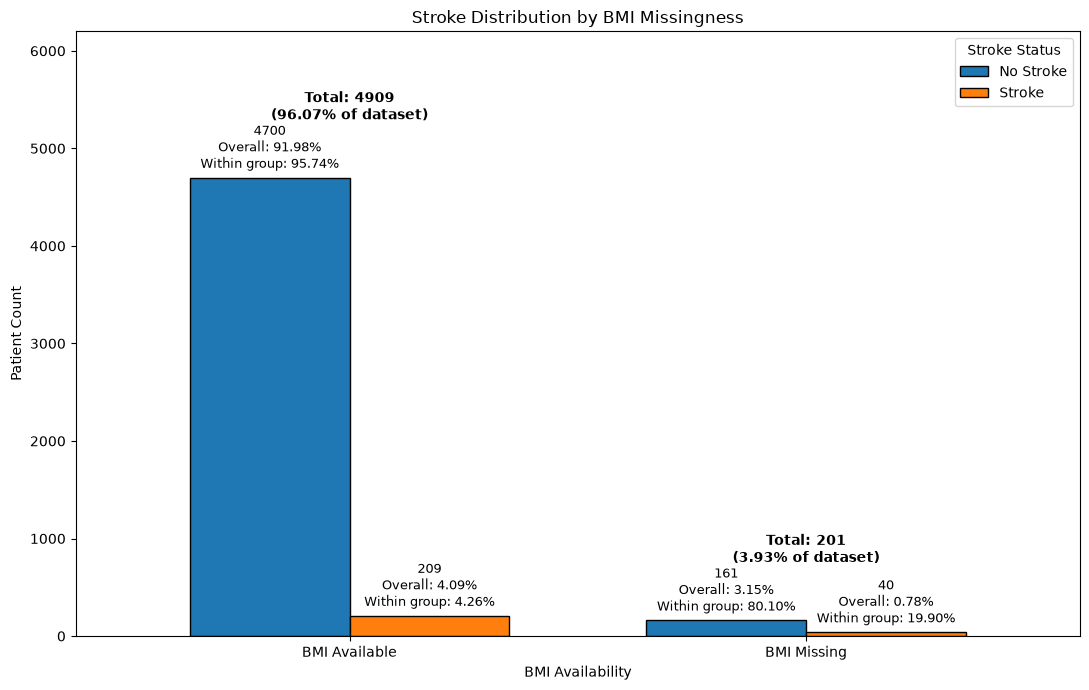

In [10]:
# Distribution of BMI Missingness over Stroke
import pandas as pd
import matplotlib.pyplot as plt

# Create BMI missingness indicator
data["BMI_Missing"] = data["bmi"].isnull()

# Count stroke cases by BMI availability
bmi_stroke = pd.crosstab(
    data["BMI_Missing"],
    data["stroke"]
).reindex(index=[False, True], columns=[0, 1], fill_value=0)

bmi_stroke.index = ["BMI Available", "BMI Missing"]
bmi_stroke.columns = ["No Stroke", "Stroke"]

# Total number of patients
total = len(data)

# Calculate category totals and stroke rates
bmi_stroke["Total"] = bmi_stroke[["No Stroke", "Stroke"]].sum(axis=1)

bmi_stroke["Stroke Rate (%)"] = (
    bmi_stroke["Stroke"] / bmi_stroke["Total"] * 100
).round(2)

print(bmi_stroke)

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bmi_stroke[["No Stroke", "Stroke"]].plot(
    kind="bar",
    ax=ax,
    edgecolor="black",
    width=0.7
)

# Add count, overall percentage and within-group percentage
for container in ax.containers:
    labels = []

    for i, bar in enumerate(container):
        count = int(bar.get_height())

        # Percentage based on full dataset
        overall_pct = count / total * 100

        # Percentage within BMI availability group
        group_total = bmi_stroke.iloc[i]["Total"]
        group_pct = count / group_total * 100

        labels.append(
            f"{count}\n"
            f"Overall: {overall_pct:.2f}%\n"
            f"Within group: {group_pct:.2f}%"
        )

    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=9
    )

# Add total count and percentage for each BMI group
for i, category in enumerate(bmi_stroke.index):

    category_total = bmi_stroke.loc[category, "Total"]
    category_pct = category_total / total * 100

    max_height = bmi_stroke.loc[
        category, ["No Stroke", "Stroke"]
    ].max()

    ax.text(
        i,
        max_height + 550,
        f"Total: {category_total}\n({category_pct:.2f}% of dataset)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Stroke Distribution by BMI Missingness")
plt.xlabel("BMI Availability")
plt.ylabel("Patient Count")
plt.xticks(rotation=0)
plt.legend(title="Stroke Status")
plt.ylim(0, 6200)
plt.tight_layout()
plt.show()

                 No Stroke  Stroke  Total  Stroke Rate (%)
smoking_status                                            
Unknown               1497      47   1544             3.04
formerly smoked        815      70    885             7.91
never smoked          1802      90   1892             4.76
smokes                 747      42    789             5.32


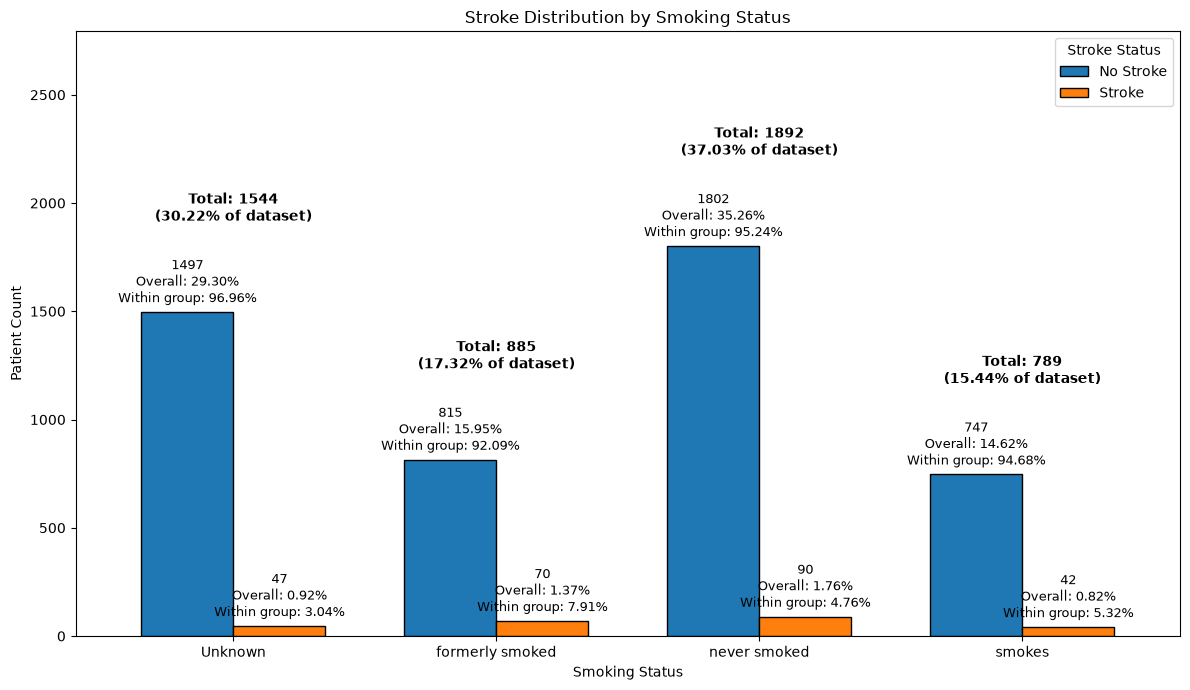

In [11]:
# Distribution of Smoking Status over Stroke
import pandas as pd
import matplotlib.pyplot as plt

# Count stroke cases by smoking status
smoking_stroke = pd.crosstab(
    data["smoking_status"].fillna("Missing"),
    data["stroke"]
)

smoking_stroke = smoking_stroke.reindex(
    columns=[0, 1],
    fill_value=0
)

smoking_stroke.columns = ["No Stroke", "Stroke"]

# Total dataset records
total = len(data)

# Total count for each smoking status category
category_totals = smoking_stroke.sum(axis=1)

# Calculate stroke rate within each category
smoking_summary = smoking_stroke.copy()
smoking_summary["Total"] = category_totals

smoking_summary["Stroke Rate (%)"] = (
    smoking_summary["Stroke"] / smoking_summary["Total"] * 100
).round(2)

print(smoking_summary)

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(12, 7))

smoking_stroke.plot(
    kind="bar",
    ax=ax,
    edgecolor="black",
    width=0.7
)

# Add count, overall percentage and within-group percentage
for container in ax.containers:
    labels = []

    for i, bar in enumerate(container):
        count = int(bar.get_height())

        # Percentage based on full dataset
        overall_pct = count / total * 100

        # Percentage within smoking status category
        group_total = category_totals.iloc[i]
        group_pct = count / group_total * 100 if group_total > 0 else 0

        labels.append(
            f"{count}\n"
            f"Overall: {overall_pct:.2f}%\n"
            f"Within group: {group_pct:.2f}%"
        )

    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=9
    )

# Add total count and percentage above each smoking category
for i, category in enumerate(smoking_stroke.index):

    category_total = category_totals.loc[category]
    category_pct = category_total / total * 100

    max_height = smoking_stroke.loc[category].max()

    ax.text(
        i,
        max_height + 400,
        f"Total: {category_total}\n"
        f"({category_pct:.2f}% of dataset)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Stroke Distribution by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Patient Count")
plt.xticks(rotation=0)
plt.legend(title="Stroke Status")

# Add space for all data labels
max_height = smoking_stroke.to_numpy().max()
plt.ylim(0, max_height * 1.55)

plt.tight_layout()
plt.show()

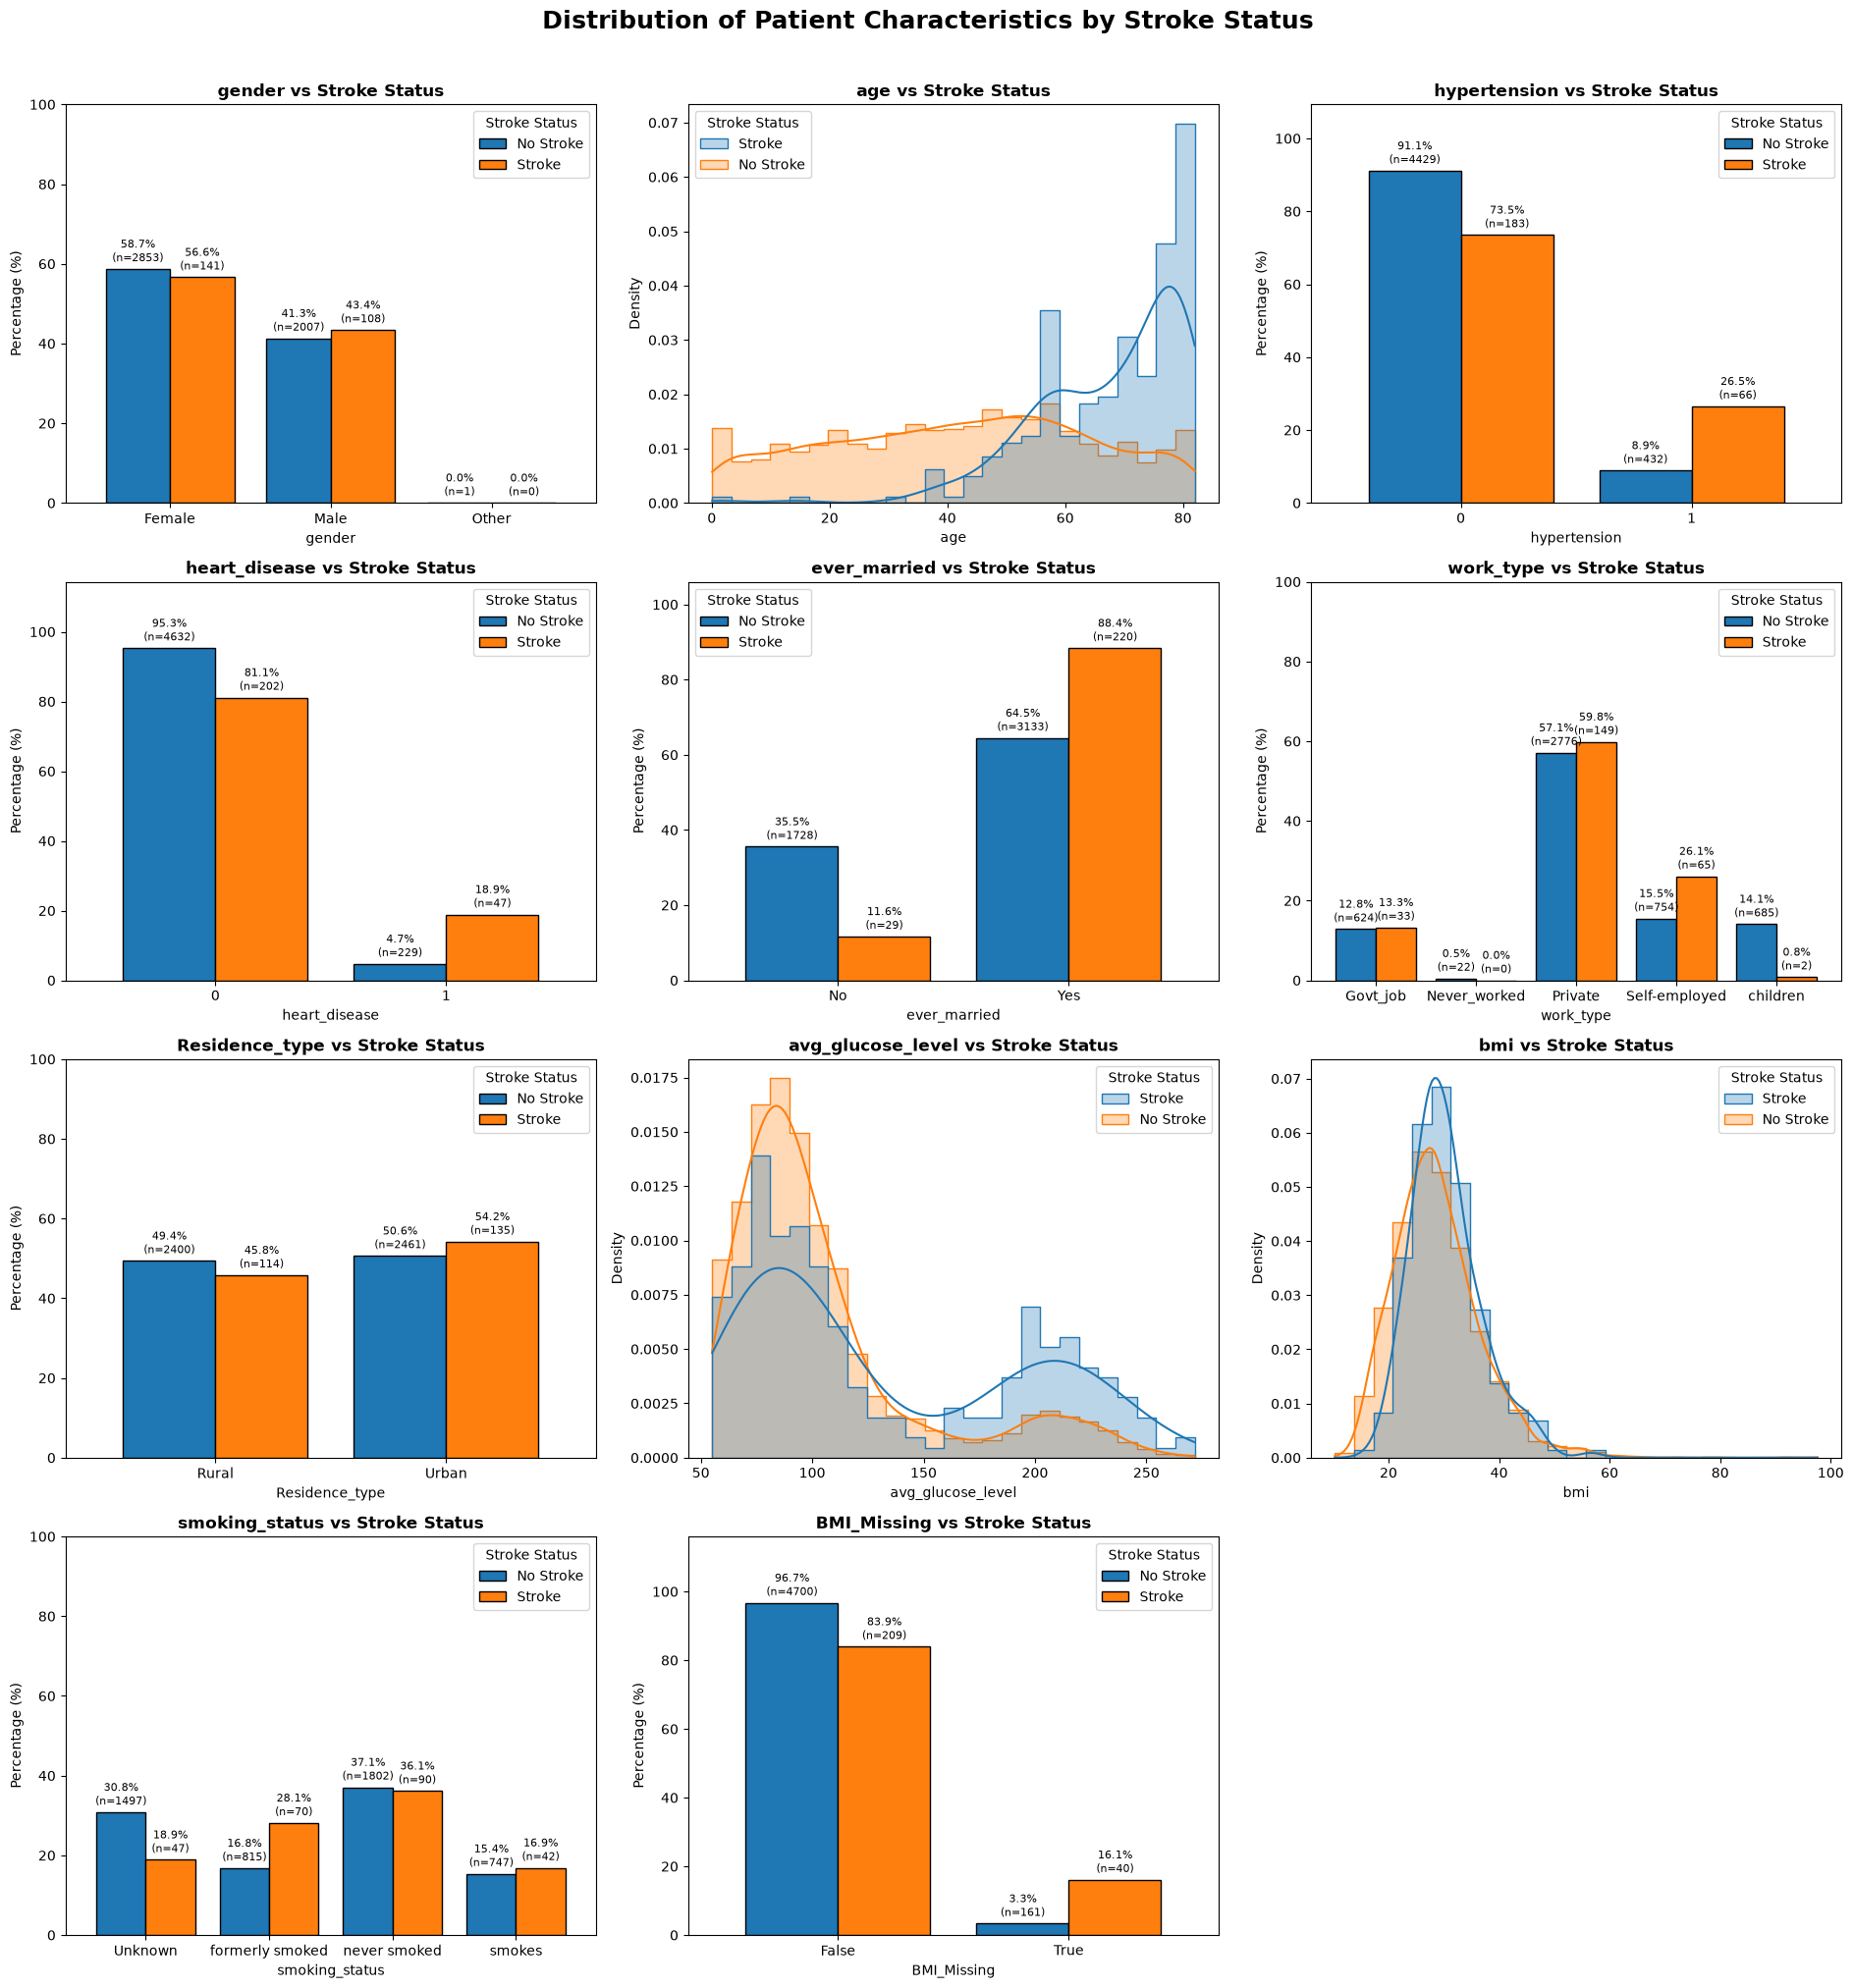

In [12]:
# Distribution of Patient Characteristics by Stroke Status
# All Columns by Stroke
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

# Define stroke labels
stroke_labels = {
    0: "No Stroke",
    1: "Stroke"
}

# Exclude ID and target column
columns = data.drop(
    columns=["id", "stroke"], errors="ignore"
).columns

# Create subplot layout
n_cols = 3
n_rows = math.ceil(len(columns) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(19, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(columns):

    ax = axes[i]

    # Numerical variables with more than 10 unique values
    if (
        pd.api.types.is_numeric_dtype(data[col])
        and data[col].nunique() > 10
    ):

        plot_data = data[[col, "stroke"]].dropna().copy()
        plot_data["Stroke Status"] = (
            plot_data["stroke"].map(stroke_labels)
        )

        sns.histplot(
            data=plot_data,
            x=col,
            hue="Stroke Status",
            bins=25,
            kde=True,
            stat="density",
            common_norm=False,
            element="step",
            alpha=0.3,
            ax=ax
        )

        ax.set_ylabel("Density")

    # Categorical and binary variables
    else:

        categories = data[col].astype("object").fillna("Missing")

        counts = pd.crosstab(
            categories,
            data["stroke"]
        ).reindex(columns=[0, 1], fill_value=0)

        percentages = (
            counts.div(counts.sum(axis=0), axis=1) * 100
        ).fillna(0)

        percentages.columns = ["No Stroke", "Stroke"]

        percentages.plot(
            kind="bar",
            ax=ax,
            edgecolor="black",
            width=0.8
        )

        # Add count and percentage labels
        for j, container in enumerate(ax.containers):
            labels = [
                f"{pct:.1f}%\n(n={count})"
                for pct, count in zip(
                    percentages.iloc[:, j],
                    counts.iloc[:, j]
                )
            ]

            ax.bar_label(
                container,
                labels=labels,
                padding=3,
                fontsize=8
            )

        ax.set_ylabel("Percentage (%)")
        ax.set_ylim(
            0,
            max(100, percentages.to_numpy().max() * 1.2)
        )
        ax.tick_params(axis="x", rotation=0)
        ax.legend(title="Stroke Status")

    ax.set_title(
        f"{col} vs Stroke Status",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(col)

# Remove unused subplots
for j in range(len(columns), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribution of Patient Characteristics by Stroke Status",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

# Task 2 Model and SHAP Explainer

This section trains a Random Forest classifier and explains its stroke-class output with SHAP TreeExplainer. The 80/20 split is stratified; median imputation and one-hot encoding are learned on training data only. Numeric features stay in their original units; only training cases are oversampled. Use a fixed random seed and rerun all cells before copying results into the report.

In [13]:
# Step 1: imports and reproducibility
import shap
import sklearn
import scipy
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import sparse
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 21
OUT = Path("output")
OUT.mkdir(exist_ok=True)
print("Versions — shap:", shap.__version__, "sklearn:", sklearn.__version__)
print("Seed:", SEED)

Versions — shap: 0.51.0 sklearn: 1.9.0
Seed: 21


In [14]:
# Step 2: prepare the raw data and split BEFORE preprocessing
loader.preprocess_data()
X_train_raw, X_test_raw, y_train, y_test = loader.get_data_split()


=== Predictors (X) ===
Shape: (5110, 10)
Predictor columns: ['age', 'avg_glucose_level', 'bmi', 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status', 'hypertension', 'heart_disease']

Train rows: 4088 
Test rows: 1022

=== Target (y) ===
Shape: (5110,)
Target column: stroke

=== Target Class Distribution ===
stroke
0    4861
1     249
Name: count, dtype: int64

Training class counts: stroke
0    3889
1     199
Name: count, dtype: int64

Testing class counts: stroke
0    972
1     50
Name: count, dtype: int64


In [15]:
# Step 3: train-fitted imputation, encoding and scaling
preprocessor = loader.get_preprocessor()
train_array = preprocessor.fit_transform(X_train_raw)
test_array = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out().tolist()
X_train = pd.DataFrame(train_array, columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(test_array, columns=feature_names, index=X_test_raw.index)
assert X_train.columns.tolist() == X_test.columns.tolist()
assert "stroke" not in X_train.columns and "id" not in X_train.columns

print("Transformed train shape:", X_train.shape)
print("Transformed test shape:", X_test.shape)
print("Features:", feature_names)

Transformed train shape: (4088, 21)
Transformed test shape: (1022, 21)
Features: ['age', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'hypertension', 'heart_disease']


In [16]:
# Step 4: oversample ONLY the training rows
oversampler = RandomOverSampler(random_state=SEED)
X_train_balanced, y_train_balanced = oversampler.fit_resample(X_train, y_train)
print("\nBefore oversampling:", y_train.value_counts().sort_index())
print("\nAfter oversampling:", y_train_balanced.value_counts().sort_index())
print("\nUntouched test set:", y_test.value_counts().sort_index())


Before oversampling: stroke
0    3889
1     199
Name: count, dtype: int64

After oversampling: stroke
0    3889
1    3889
Name: count, dtype: int64

Untouched test set: stroke
0    972
1     50
Name: count, dtype: int64


## Model development

In [17]:
# Step 5: fit a black-box classifier
rf = RandomForestClassifier(n_estimators=100, random_state=SEED)  # reproducible reruns
rf.fit(X_train_balanced, y_train_balanced)
positive_index = list(rf.classes_).index(1)
print("Model: RandomForestClassifier")
print("Class order:", rf.classes_.tolist(), "| stroke-positive index:", positive_index)
print("Parameters:", rf.get_params())

Model: RandomForestClassifier
Class order: [0, 1] | stroke-positive index: 1
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': 21, 'verbose': 0, 'warm_start': False}


,Metric,Result
0,Accuracy,0.940313
1,Balanced Accuracy,0.532284
2,Precision (stroke=1),0.210526
3,Recall (stroke=1),0.080000
4,F1-Score (stroke=1),0.115942
5,ROC AUC,0.768745
6,Average Precision,0.129590
7,Positive Support,50.000000
8,Threshold,0.500000
9,TN,957.000000



Positive-class classification report:
               precision    recall  f1-score   support

           0       0.95      0.98      0.97       972
           1       0.21      0.08      0.12        50

    accuracy                           0.94      1022
   macro avg       0.58      0.53      0.54      1022
weighted avg       0.92      0.94      0.93      1022

Missed recorded stroke cases (FN): 46 of 50


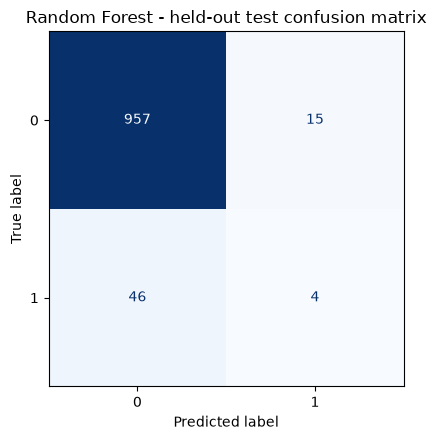

In [18]:
# Step 6: held-out evaluation (threshold selected in advance)
THRESHOLD = 0.5
y_prob = rf.predict_proba(X_test)[:, positive_index]
y_pred = (y_prob >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (stroke=1)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (stroke=1)": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score (stroke=1)": f1_score(y_test, y_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob),
    "Positive Support": int((y_test == 1).sum()),
    "Threshold": THRESHOLD,
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
}

metrics_table = pd.DataFrame({"Metric": list(results), "Result": list(results.values())})
display(metrics_table)
print("\nPositive-class classification report:\n", classification_report(y_test, y_pred, zero_division=0))
print(f"Missed recorded stroke cases (FN): {fn} of {(y_test == 1).sum()}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1], ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Random Forest - held-out test confusion matrix")
fig.tight_layout()
plt.show()

# Task 3 Local Explanation Using a Force Plot

In [19]:
# Find patients with Actual = 1 and Predicted = 0
false_negative = X_test.loc[
    (y_test == 1) & (y_pred == 0)
].copy()

# Add actual and predicted labels
false_negative["Actual_Stroke"] = 1
false_negative["RF_Prediction"] = 0

# Add stroke probability
positive_index = list(rf.classes_).index(1)

false_negative["Stroke_Probability"] = rf.predict_proba(
    X_test.loc[false_negative.index]
)[:, positive_index]

print("Total False Negative Patients:", len(false_negative))
display(false_negative)

Total False Negative Patients: 46


,age,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,hypertension,heart_disease,Actual_Stroke,RF_Prediction,Stroke_Probability
137,76.0,207.28,34.9,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1,0,0.10
159,81.0,74.02,25.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1,0,0.46
52,79.0,127.29,27.7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1,0,0.04
133,38.0,101.45,28.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1,0,0.01
190,65.0,205.77,46.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1,0,0.17
94,45.0,64.14,29.4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0.01
95,78.0,235.63,32.3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0.14
140,82.0,103.68,25.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1,0,0.20
13,78.0,219.84,28.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1,0,0.23
194,72.0,97.92,26.9,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0,0.05


In [20]:
# Step 7: Select one false-negative patient and time local Tree SHAP
import time
import shap
from IPython.display import display
shap.initjs()

false_negative = X_test.loc[(y_test == 1) & (y_pred == 0)]
print("False-negative cases in held-out set:", len(false_negative))
if false_negative.empty:
    raise ValueError("No false-negative cases were found; document another case type.")

# The selected patient is reproducible when the model uses a fixed random seed.
X_local = false_negative.sample(n=1, random_state=SEED)
patient_index = X_local.index[0]
explainer = shap.TreeExplainer(rf)  # reference: training tree paths

rf_local_start = time.perf_counter()
local_shap = explainer(X_local)
stroke_local = local_shap[..., positive_index]  # stroke = 1
rf_local_runtime = time.perf_counter() - rf_local_start

local_rf_prob = float(rf.predict_proba(X_local)[0, positive_index])
print("Patient index:", patient_index)
print("Actual stroke:", int(y_test.loc[patient_index]))
print("RF predicted class:", int(rf.predict(X_local)[0]))
print(f"RF stroke-class probability: {local_rf_prob:.6f}")
print(f"RF local SHAP computation time: {rf_local_runtime:.4f} seconds")
display(shap.plots.force(stroke_local[0]))

False-negative cases in held-out set: 46
Patient index: 75
Actual stroke: 1
RF predicted class: 0
RF stroke-class probability: 0.180000
RF local SHAP computation time: 0.0114 seconds


In [21]:
# Step 7.1: Export SHAP Force Plot as PNG
# Generate a static SHAP force plot
shap.plots.force(
    stroke_local[0],
    matplotlib=True,
    show=False
)

# Save as high-resolution PNG
plt.savefig(
    f"{OUT}/task3_shap_force_patient_{patient_index}.png",
    dpi=300,
    bbox_inches="tight"
)


print("SHAP force plot exported successfully.")

SHAP force plot exported successfully.


In [22]:
# Step 7.2: Export interactive SHAP Force Plot
force_plot = shap.plots.force(stroke_local[0])

shap.save_html(
    f"{OUT}/task3_shap_force_patient_{patient_index}.html",
    force_plot
)

print(f"SHAP force plot saved to: {OUT / f'task3_shap_force_patient_{patient_index}.html'}")

SHAP force plot saved to: output\task3_shap_force_patient_75.html


In [23]:

# Step 8 - SHAP Verification and Interpretation
import numpy as np
import pandas as pd

# Use the selected patient from Step 7
# local_shap = explainer(X_local)
# positive_index = list(rf.classes_).index(1)
# stroke_local = local_shap[..., positive_index]

# 1. Verify feature dimensions
print("=== SHAP Verification ===")
print("Input Shape:", X_local.shape)
print("SHAP Shape:", stroke_local.values.shape)
print("Feature Names:", X_local.columns.tolist())
print("Explained Class:", rf.classes_[positive_index])
print("Output Scale: Probability")

# 2. Verify SHAP additivity
base_value = float(stroke_local[0].base_values)
shap_sum = stroke_local[0].values.sum()
reconstructed = base_value + shap_sum
model_output = rf.predict_proba(X_local)[0, positive_index]
residual = abs(model_output - reconstructed)

print("\n=== Additivity Check ===")
print(f"Base Value: {base_value:.6f}")
print(f"Sum of SHAP Values: {shap_sum:.6f}")
print(f"Reconstructed Output: {reconstructed:.6f}")
print(f"Model Output: {model_output:.6f}")
print(f"Residual: {residual:.8f}")
print("Additivity Verified:", residual < 1e-4)

# 3. Interpret feature contributions
print("\n=== SHAP Interpretation ===")

contributions = pd.DataFrame({
    "Feature": X_local.columns,
    "Patient Value": X_local.iloc[0].values,
    "SHAP Value": stroke_local[0].values
})

contributions["Direction"] = np.where(
    contributions["SHAP Value"] > 0,
    "Increases",
    "Decreases"
)

# Sort by absolute SHAP contribution
contributions = contributions.reindex(
    contributions["SHAP Value"].abs()
    .sort_values(ascending=False).index
)

# Display SHAP values with 4 decimal places
display(
    contributions.style.format({
        "SHAP Value": "{:.4f}"
    })
)


=== SHAP Verification ===
Input Shape: (1, 21)
SHAP Shape: (1, 21)
Feature Names: ['age', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'hypertension', 'heart_disease']
Explained Class: 1
Output Scale: Probability

=== Additivity Check ===
Base Value: 0.499659
Sum of SHAP Values: -0.319659
Reconstructed Output: 0.180000
Model Output: 0.180000
Residual: 0.00000000
Additivity Verified: True

=== SHAP Interpretation ===


,Feature,Patient Value,SHAP Value,Direction
2,bmi,21.700000,-0.1525,Decreases
1,avg_glucose_level,66.720000,-0.1050,Decreases
0,age,80.000000,0.0552,Increases
19,hypertension,0.000000,-0.0352,Decreases
11,work_type_Self-employed,1.000000,-0.0203,Decreases
10,work_type_Private,0.000000,-0.0168,Decreases
17,smoking_status_never smoked,0.000000,-0.0132,Decreases
15,smoking_status_Unknown,0.000000,-0.0121,Decreases
4,gender_Male,0.000000,-0.0098,Decreases
3,gender_Female,1.000000,-0.0072,Decreases


# Task 4 - Global Explanation Using a Summary Plot

The Random Forest **Tree SHAP** explanation covers **all 1,022 held-out test patients**, including the 50 recorded-stroke cases. All 21 transformed features are included; the plots display the 15 largest contributors. The SHAP background uses the fitted trees' path statistics from oversampled training data. Local and global SHAP computation times are measured separately.

Tree SHAP background: fitted tree-path statistics (oversampled training)
Global explanation sample: 1022 held-out test patients
Recorded stroke cases: 50
Number of features: 21
Explained output: stroke = 1 probability (0-1)
RF local SHAP:  0.0114 seconds
RF global SHAP: 10.3619 seconds
RF combined:    10.3733 seconds


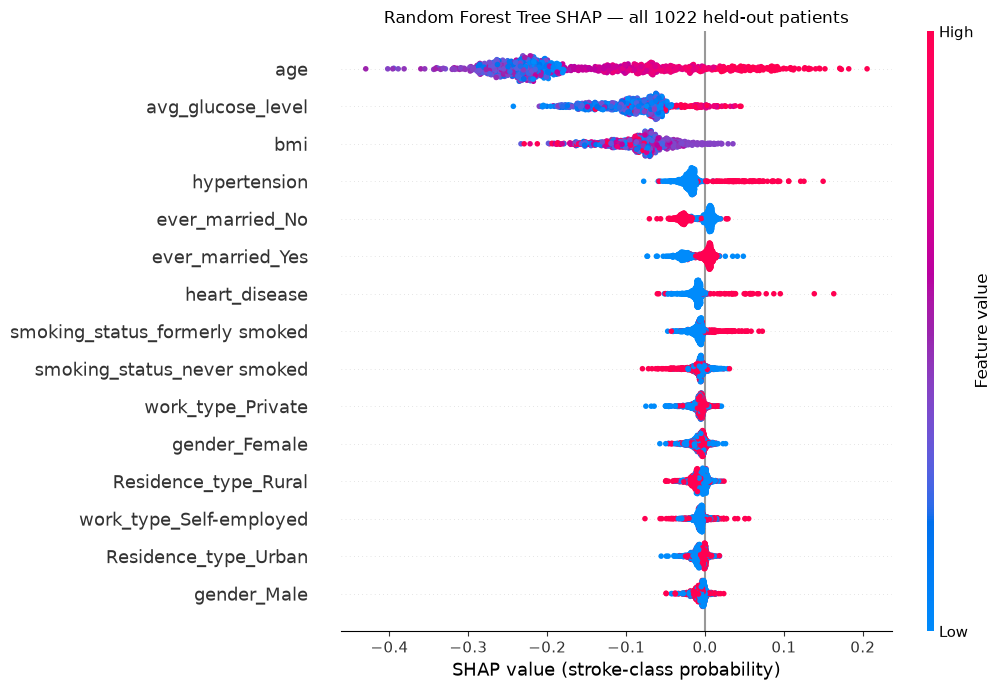

In [25]:
# Task 4: Global Tree SHAP for ALL held-out test patients (no sampling)
import time

X_explain = X_test.copy()
assert X_explain.index.equals(X_test.index)
assert len(X_explain) == len(y_test)

rf_global_start = time.perf_counter()
shap_values = explainer(X_explain)
stroke_shap = shap_values[..., positive_index]  # output: stroke = 1 probability
rf_global_runtime = time.perf_counter() - rf_global_start
rf_total_runtime = rf_local_runtime + rf_global_runtime

assert stroke_shap.values.shape == (len(X_test), len(feature_names))
print("Tree SHAP background: fitted tree-path statistics (oversampled training)")
print("Global explanation sample:", len(X_explain), "held-out test patients")
print("Recorded stroke cases:", int(y_test.loc[X_explain.index].sum()))
print("Number of features:", stroke_shap.values.shape[1])
print("Explained output: stroke = 1 probability (0-1)")
print(f"RF local SHAP:  {rf_local_runtime:.4f} seconds")
print(f"RF global SHAP: {rf_global_runtime:.4f} seconds")
print(f"RF combined:    {rf_total_runtime:.4f} seconds")

# Plot colours show feature values, not a medical severity scale.
shap.summary_plot(
    stroke_shap.values,
    X_explain,
    max_display=15,
    show=False
)
plt.gcf().set_size_inches(10.5, 7)
plt.title(f"Random Forest Tree SHAP — all {len(X_explain)} held-out patients")
plt.xlabel("SHAP value (stroke-class probability)")
plt.tight_layout()
plt.savefig(OUT / "task4_shap_beeswarm.png", dpi=220, bbox_inches="tight")
plt.show()

Held-out explanation sample: 1022 patients
Stroke-positive cases: 50


,Rank,Feature,Mean Absolute SHAP
0,1,age,0.170762
1,2,avg_glucose_level,0.090230
2,3,bmi,0.080548
3,4,hypertension,0.022570
4,5,ever_married_No,0.013818


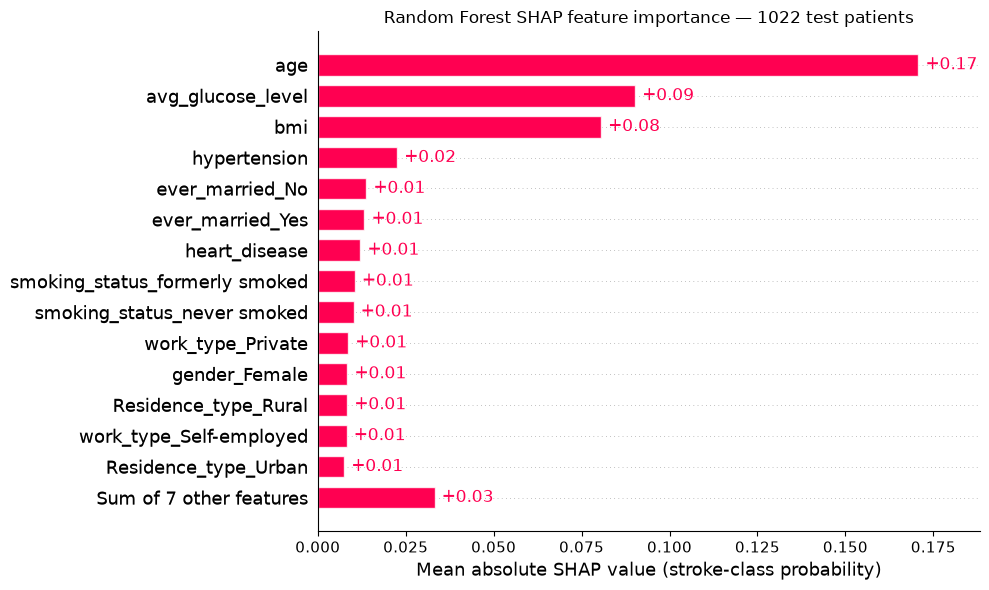

In [26]:
# Task 4 - Global feature importance across ALL 1,022 held-out patients
importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean Absolute SHAP": np.abs(stroke_shap.values).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False).reset_index(drop=True)
importance.insert(0, "Rank", np.arange(1, len(importance) + 1))

print("Held-out explanation sample:", len(X_explain), "patients")
print("Stroke-positive cases:", int(y_test.loc[X_explain.index].sum()))
display(importance.head(5))
importance.to_csv(OUT / "task4_feature_importance.csv", index=False)

shap.plots.bar(stroke_shap, max_display=15, show=False)
plt.gcf().set_size_inches(10, 6)
plt.title(f"Random Forest SHAP feature importance — {len(X_explain)} test patients")
plt.xlabel("Mean absolute SHAP value (stroke-class probability)")
plt.tight_layout()
plt.savefig(OUT / "task4_shap_importance.png", dpi=220, bbox_inches="tight")
plt.show()


# Task 5 Plan for Three Audience Slides

In [27]:
# Task 5: Export interactive SHAP force plot as HTML
import shap
from pathlib import Path
from IPython.display import display

OUT = Path("output")
OUT.mkdir(parents=True, exist_ok=True)

# Reuse patient and SHAP results from Task 3
assert patient_index == 75, "Patient index does not match Task 3."

# Plain-language feature names
friendly_names = {
    "age": "Age (years)",
    "avg_glucose_level": "Average glucose (mg/dL)",
    "bmi": "Body mass index (BMI)",
    "hypertension": "High blood pressure recorded",
    "heart_disease": "Heart disease recorded",
    "ever_married_Yes": "Married",
    "ever_married_No": "Not married",
    "smoking_status_formerly smoked": "Previously smoked",
    "smoking_status_never smoked": "Never smoked",
    "smoking_status_smokes": "Currently smokes",
    "smoking_status_Unknown": "Smoking status unavailable"
}

friendly_features = [
    friendly_names.get(col, col.replace("_", " "))
    for col in X_local.columns
]

# Generate interactive force plot using Task 3 SHAP values
force_plot = shap.force_plot(
    base_value=float(stroke_local[0].base_values),
    shap_values=stroke_local[0].values,
    features=X_local.iloc[0].values,
    feature_names=friendly_features,
    matplotlib=False
)

# Display interactive plot in Jupyter Notebook
shap.initjs()
display(force_plot)

# Export interactive HTML
html_path = OUT / f"task5_patient_{patient_index}_force_plain_language.html"

shap.save_html(str(html_path), force_plot)

print("Interactive SHAP Force Plot exported:")
print(html_path.resolve())

Interactive SHAP Force Plot exported:
C:\Users\user\OneDrive\0. Master Degree\1. Sem 1 2026_2027\Assignment\XAI\Stroke_Prediction\output\task5_patient_75_force_plain_language.html


Patient Index: 75
Actual Stroke: 1
Predicted Stroke: 0
Stroke Probability: 0.1800


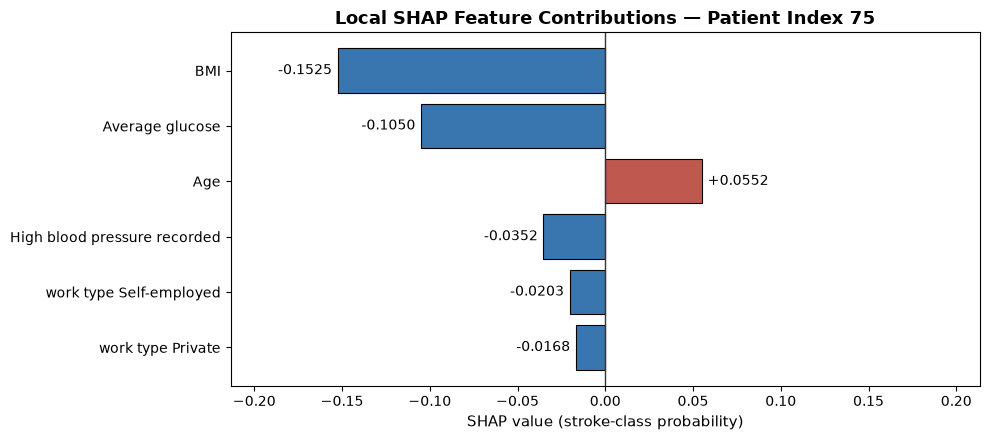


=== Local SHAP Feature Contributions ===


,feature,SHAP,value,label
2,bmi,-0.152513,21.70,BMI
1,avg_glucose_level,-0.105009,66.72,Average glucose
0,age,+0.055181,80.00,Age
19,hypertension,-0.035220,0.00,High blood pressure recorded
11,work_type_Self-employed,-0.020333,1.00,work type Self-employed
10,work_type_Private,-0.016804,0.00,work type Private
17,smoking_status_never smoked,-0.013212,0.00,Never smoked
15,smoking_status_Unknown,-0.012055,0.00,Smoking status unavailable
4,gender_Male,-0.009825,0.00,gender Male
3,gender_Female,-0.007244,1.00,gender Female



Exported:
output\task5_patient_75_force.png
output\task5_patient_75_factors.png


In [28]:
# Patient Index 75 - Local SHAP Explanation
# Export force plot and patient feature contributions with data labels

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from pathlib import Path

OUT = Path("output")
OUT.mkdir(parents=True, exist_ok=True)

# Step 1: Select patient index 75
patient_index = 75
X_local = X_test.loc[[patient_index]]

# Verify the selected patient
actual_class = int(y_test.loc[patient_index])
predicted_class = int(rf.predict(X_local)[0])
stroke_probability = float(
    rf.predict_proba(X_local)[0, positive_index]
)

print("Patient Index:", patient_index)
print("Actual Stroke:", actual_class)
print("Predicted Stroke:", predicted_class)
print(f"Stroke Probability: {stroke_probability:.4f}")

# Step 2: Calculate local Tree SHAP
local_shap = explainer(X_local)
stroke_local = local_shap[..., positive_index]

# Step 3: Define reader-friendly feature names
friendly_names = {
    "age": "Age",
    "avg_glucose_level": "Average glucose",
    "bmi": "BMI",
    "hypertension": "High blood pressure recorded",
    "heart_disease": "Heart disease recorded",
    "ever_married_Yes": "Married",
    "ever_married_No": "Not married",
    "smoking_status_formerly smoked": "Previously smoked",
    "smoking_status_never smoked": "Never smoked",
    "smoking_status_smokes": "Currently smokes",
    "smoking_status_Unknown": "Smoking status unavailable"
}

# Step 4: Prepare SHAP contributions
local_contrib = pd.DataFrame({
    "feature": X_local.columns,
    "SHAP": stroke_local.values[0],
    "value": X_local.iloc[0].values
})

local_contrib["label"] = (
    local_contrib["feature"]
    .map(friendly_names)
    .fillna(
        local_contrib["feature"].str.replace("_", " ", regex=False)
    )
)

# Sort by absolute SHAP contribution
local_contrib = local_contrib.reindex(
    local_contrib["SHAP"].abs()
    .sort_values(ascending=False).index
)

# Step 5: Export local SHAP force plot
# Show strongest four features and combine remaining contributions

most = local_contrib.head(4)
remaining = float(local_contrib.iloc[4:]["SHAP"].sum())

plot_shap = np.r_[
    most["SHAP"].to_numpy(),
    remaining
]

plot_values = (
    list(most["value"].round(2).astype(str))
    + ["combined"]
)

plot_names = most["label"].tolist() + ["Other features"]

shap.force_plot(
    float(stroke_local[0].base_values),
    plot_shap,
    features=pd.Series(plot_values, index=plot_names),
    matplotlib=True,
    show=False,
    figsize=(14.5, 3.5),
    contribution_threshold=0.0
)

plt.savefig(
    OUT / f"task5_patient_{patient_index}_force.png",
    dpi=220,
    bbox_inches="tight"
)
plt.close()

# Step 6: Plot top 6 SHAP contributions with data labels
top_patient = local_contrib.head(6).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4.5))

colors = [
    "#BF594F" if v > 0 else "#3976AF"
    for v in top_patient["SHAP"]
]

bars = ax.barh(
    top_patient["label"],
    top_patient["SHAP"],
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

# Add SHAP value labels (4 decimal places)
ax.bar_label(
    bars,
    labels=[
        f"{v:+.4f}"
        for v in top_patient["SHAP"]
    ],
    padding=4,
    fontsize=10
)

# Add space to prevent labels from being cut off
max_abs = top_patient["SHAP"].abs().max()

ax.set_xlim(
    -max_abs * 1.4,
    max_abs * 1.4
)

# Reference line at zero
ax.axvline(
    0,
    color="#333333",
    linewidth=1
)

ax.set_xlabel(
    "SHAP value (stroke-class probability)",
    fontsize=11
)

ax.set_title(
    f"Local SHAP Feature Contributions — Patient Index {patient_index}",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

# Save patient contribution chart
fig.savefig(
    OUT / f"task5_patient_{patient_index}_factors.png",
    dpi=220,
    bbox_inches="tight"
)

plt.show()

# Step 7: Display feature contributions
print("\n=== Local SHAP Feature Contributions ===")

display(
    local_contrib.style.format({
        "SHAP": "{:+.6f}",
        "value": "{:.2f}"
    })
)

# Step 8: Confirm exported files
print("\nExported:")
print(OUT / f"task5_patient_{patient_index}_force.png")
print(OUT / f"task5_patient_{patient_index}_factors.png")

# Task 6 Explain a Different Black Box Model

Train a **different black-box model**, an RBF Support Vector Machine (SVM), with the **same 80/20 stratified split and the same 21 encoded predictors** as the Random Forest. The SVM additionally standardises numerical columns using training-only statistics. Both models are evaluated on all 1,022 held-out records.

For Kernel SHAP, use a **30-row reference background sampled from the original training set**, not test data. The local explanation uses the same selected patient as Task 3; the global explanation covers **all 1,022 test patients**. Due to the computational cost, the global SVM explanations are calculated in resumable batches with cached results and separately recorded local/global computation times.

The background and explanation population are different concepts: the **background** defines the reference prediction; the **test sample** contains the cases being explained. A new SHAP background does not retrain the SVM or change its performance metrics.

In [29]:
# Step 1: fit on RBF SVM, using comparable data with training-only scaling
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

numerical_cols = ["age", "avg_glucose_level", "bmi"]
svm_scaler = StandardScaler().fit(X_train[numerical_cols]) # training only

def svm_scaled(frame):
    out = frame.copy()
    out.loc[:, numerical_cols] = svm_scaler.transform(frame[numerical_cols])
    return out

X_train_svm = svm_scaled(X_train) # original training distribution
X_balanced_svm = svm_scaled(X_train_balanced) # same balanced training cases as RF
X_test_svm = svm_scaled(X_test)

svm = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=SEED)
svm.fit(X_balanced_svm, y_train_balanced)
svm_post_index = list(svm.classes_).index(1)

print("Model: ", svm)
print("Train rows: ", len(X_balanced_svm), " | Test rows: ", len(X_test_svm))
print("Feature names identical: ", X_test_svm.columns.equals(X_test.columns))
print("Output class: ", svm.classes_[svm_post_index])

c:\Users\user\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Model:  SVC(probability=True, random_state=21)
Train rows:  7778  | Test rows:  1022
Feature names identical:  True
Output class:  1


,Metric,Result
0,Accuracy,0.769080
1,Balanced Accuracy,0.669918
2,Precision (stroke=1),0.115702
3,Recall (stroke=1),0.560000
4,F1-Score (stroke=1),0.191781
5,ROC AUC,0.782407
6,Average Precision,0.166627
7,Positive Support,50.000000
8,TN,758.000000
9,FP,214.000000


SVM confusion matrix (TN, FP, FN, TP):  758 214 22 28


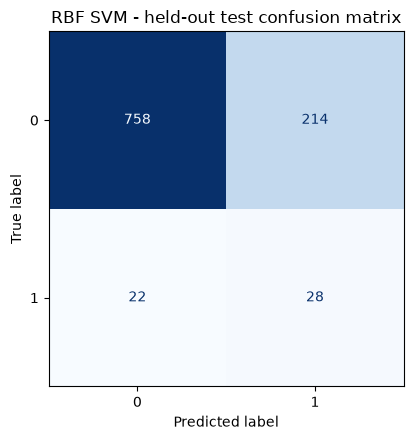

In [30]:
# Step 2: held-out SVM performance (default prediction decision rule)
svm_pred = svm.predict(X_test_svm)
svm_prob = svm.predict_proba(X_test_svm)[:, svm_post_index]
svm_tn, svm_fp, svm_fn, svm_tp = confusion_matrix(
    y_test, svm_pred, labels=[0, 1]
).ravel()

svm_results = {
    "Accuracy": accuracy_score(y_test, svm_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, svm_pred),
    "Precision (stroke=1)": precision_score(y_test, svm_pred, zero_division=0),
    "Recall (stroke=1)": recall_score(y_test, svm_pred, zero_division=0),
    "F1-Score (stroke=1)": f1_score(y_test, svm_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, svm_prob),
    "Average Precision": average_precision_score(y_test, svm_prob),
    "Positive Support": int((y_test == 1).sum()),
    "TN": int(svm_tn), "FP": int(svm_fp),
    "FN": int(svm_fn), "TP": int(svm_tp)
}

display(pd.DataFrame({"Metric": list(svm_results), "Result": list(svm_results.values())}))
print("SVM confusion matrix (TN, FP, FN, TP): ", svm_tn, svm_fp, svm_fn, svm_tp)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, svm_pred, labels=[0, 1],
                                        ax=ax, cmap="Blues", colorbar=False)

ax.set_title("RBF SVM - held-out test confusion matrix")
fig.tight_layout()
fig.savefig(OUT / "task6_svm_confusion.png", dpi=220, bbox_inches="tight")
plt.show()

In [31]:
# Step 3: RBF SVM Kernel SHAP for ALL 1,022 held-out test patients
# Background: 30 original TRAINING records (not the test set; no oversampling)
# Global explanations: ALL original held-out test records (no sampling)
# Runtime is recorded separately for local and global computations.
# To protect against interruptions, global results are cached in 20-row batches.

import hashlib
import time
from joblib import hash as joblib_hash

KERNEL_BACKGROUND_N = 30
KERNEL_NSAMPLES = 96
KERNEL_BATCH_SIZE = 20  # lower to 5 or 10 if memory is limited

background_svm = X_train_svm.sample(
    n=min(KERNEL_BACKGROUND_N, len(X_train_svm)), random_state=SEED
)
X_task6_original = X_test.copy()   # original feature values for readable plots
X_task6_svm = X_test_svm.copy()    # SVM-scaled feature values for explanation
X_local_svm = X_test_svm.loc[X_local.index]

assert X_task6_svm.index.equals(X_task6_original.index)
assert list(background_svm.columns) == list(feature_names)
assert list(X_task6_svm.columns) == list(feature_names)


def svm_stroke_probability(values):
    # Kernel SHAP passes a NumPy array. Recreate the labelled columns in order.
    frame = pd.DataFrame(np.asarray(values), columns=feature_names)
    return svm.predict_proba(frame)[:, svm_post_index]


def as_svm_shap_2d(values, rows):
    values = np.asarray(values)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[..., 0]
    expected = (rows, len(feature_names))
    if values.shape != expected:
        raise ValueError(f"Kernel SHAP shape {values.shape} != {expected}")
    return values


np.random.seed(SEED)
kernel_explainer = shap.KernelExplainer(
    svm_stroke_probability, background_svm, link="identity"
)

# Local Kernel SHAP for the same patient selected in Task 3
svm_local_start = time.perf_counter()
svm_local_values = as_svm_shap_2d(
    kernel_explainer.shap_values(
        X_local_svm,
        nsamples=KERNEL_NSAMPLES,
        l1_reg="num_features(10)",
        silent=True
    ), len(X_local_svm)
)
svm_local_runtime = time.perf_counter() - svm_local_start

# Keep cached batches separate for each fitted SVM and dataset configuration.
# This prevents accidentally reusing SHAP values after retraining the model.
cache_hash = hashlib.sha256()
settings = (joblib_hash(svm), str(SEED), str(KERNEL_NSAMPLES),
            str(KERNEL_BATCH_SIZE), shap.__version__,
            "num_features(10)", "identity", "|".join(feature_names))
cache_hash.update("::".join(settings).encode("utf-8"))
for frame in (background_svm, X_task6_svm):
    cache_hash.update(np.asarray(frame.to_numpy(), dtype=np.float64).tobytes())
    cache_hash.update(str(tuple(frame.index)).encode("utf-8"))

cache_dir = OUT / "task6_kernel_shap_batches" / cache_hash.hexdigest()[:16]
cache_dir.mkdir(parents=True, exist_ok=True)
print("Saving / reading Kernel SHAP batches in:", cache_dir)
print("SVM Kernel SHAP patients:", len(X_task6_svm),
      "| Training background:", len(background_svm))

# Global Kernel SHAP. Each saved batch contains feature contributions and its
# original calculation time. Re-running this cell resumes completed batches.
svm_global_values_parts = []
global_batch_times = []
for start in range(0, len(X_task6_svm), KERNEL_BATCH_SIZE):
    stop = min(start + KERNEL_BATCH_SIZE, len(X_task6_svm))
    checkpoint = cache_dir / f"shap_{start:04d}_{stop:04d}.npz"

    if checkpoint.is_file():
        with np.load(checkpoint, allow_pickle=False) as saved:
            batch_values = np.asarray(saved["values"])
            batch_runtime = float(saved["elapsed"])
        if batch_values.shape != (stop - start, len(feature_names)):
            raise ValueError(f"Invalid cached SHAP dimensions in {checkpoint}")
    else:
        # Fixed seed for each batch, including after a notebook restart.
        np.random.seed(SEED + start)
        batch_start = time.perf_counter()
        batch_values = as_svm_shap_2d(
            kernel_explainer.shap_values(
                X_task6_svm.iloc[start:stop],
                nsamples=KERNEL_NSAMPLES,
                l1_reg="num_features(10)",
                silent=True
            ), stop - start
        )
        batch_runtime = time.perf_counter() - batch_start
        # Write a temporary file first, then replace atomically.
        temp_file = checkpoint.with_suffix(".tmp.npz")
        np.savez_compressed(temp_file, values=batch_values, elapsed=batch_runtime)
        temp_file.replace(checkpoint)

    svm_global_values_parts.append(batch_values)
    global_batch_times.append(batch_runtime)
    print(f"Kernel SHAP: {stop:,}/{len(X_task6_svm):,} test patients ready", end="\r")

svm_global_values = np.vstack(svm_global_values_parts)
svm_global_runtime = float(sum(global_batch_times))
svm_kernel_runtime = svm_local_runtime + svm_global_runtime
print()  # newline after the progress indicator

assert svm_global_values.shape == (len(X_task6_svm), len(feature_names))
assert svm_local_values.shape == (len(X_local_svm), len(feature_names))

# Local additivity: SHAP baseline + feature contributions = SVM class-1 probability
svm_local_base = float(kernel_explainer.expected_value)
svm_local_recon = float(svm_local_base + svm_local_values[0].sum())
svm_local_model = float(svm_stroke_probability(X_local_svm)[0])
svm_residual = abs(svm_local_recon - svm_local_model)

# Check additivity for ALL global test explanations.
svm_global_reconstructed = svm_local_base + svm_global_values.sum(axis=1)
svm_global_probabilities = svm_stroke_probability(X_task6_svm)
svm_global_residuals = np.abs(svm_global_reconstructed - svm_global_probabilities)

print("\n=== RBF SVM Kernel SHAP Results ===")
print("Explained class: stroke = 1 | Output scale: probability (0-1)")
print("Training background:", len(background_svm), "rows")
print("Global test explanations:", len(X_task6_svm), "patients")
print("Local test explanations:", len(X_local_svm), "patient")
print("Stroke-positive patients in global set:", int(y_test.loc[X_task6_svm.index].sum()))
print("Local SHAP shape:", svm_local_values.shape)
print("Global SHAP shape:", svm_global_values.shape)
print("Selected patient:", patient_index,
      "| Actual:", int(y_test.loc[patient_index]),
      "| Predicted:", int(svm.predict(X_local_svm)[0]))
print(f"Base value: {svm_local_base:.6f}")
print(f"Local SHAP sum: {svm_local_values[0].sum():.6f}")
print(f"Reconstructed prediction: {svm_local_recon:.6f}")
print(f"SVM probability: {svm_local_model:.6f}")
print(f"Local residual: {svm_residual:.8f}")
print(f"Maximum global residual: {svm_global_residuals.max():.8f}")
print("Global explanations verified:", bool((svm_global_residuals < 1e-4).all()))
print(f"Local SHAP computation: {svm_local_runtime:.2f} seconds")
print(f"Global SHAP computation: {svm_global_runtime:.2f} seconds")
print(f"Total SHAP computation: {svm_kernel_runtime:.2f} seconds")
print("Note: global runtime adds original calculation times of all batches,")
print("including batches loaded from cache after an interrupted run.")

Saving / reading Kernel SHAP batches in: output\task6_kernel_shap_batches\abc33a30cc604000
SVM Kernel SHAP patients: 1022 | Training background: 30
Kernel SHAP: 1,022/1,022 test patients ready

=== RBF SVM Kernel SHAP Results ===
Explained class: stroke = 1 | Output scale: probability (0-1)
Training background: 30 rows
Global test explanations: 1022 patients
Local test explanations: 1 patient
Stroke-positive patients in global set: 50
Local SHAP shape: (1, 21)
Global SHAP shape: (1022, 21)
Selected patient: 75 | Actual: 1 | Predicted: 1
Base value: 0.369148
Local SHAP sum: 0.352537
Reconstructed prediction: 0.721685
SVM probability: 0.721685
Local residual: 0.00000000
Maximum global residual: 0.00000000
Global explanations verified: True
Local SHAP computation: 0.50 seconds
Global SHAP computation: 1180.40 seconds
Total SHAP computation: 1180.90 seconds
Note: global runtime adds original calculation times of all batches,
including batches loaded from cache after an interrupted run.


In [32]:
# Step 3.1: Export Kernel SHAP Force Plot as HTML
import shap
from pathlib import Path

OUT = Path("output")
OUT.mkdir(parents=True, exist_ok=True)

filename = f"task6_kernel_shap_force_patient_{patient_index}.html"

# Generate interactive SHAP force plot
force_html = shap.force_plot(
    svm_local_base,
    svm_local_values[0],
    X_local.iloc[0],
    feature_names=feature_names,
    matplotlib=False
)

# Save as HTML
html_path = OUT / filename
shap.save_html(str(html_path), force_html)

print(f"SHAP Force Plot saved to: {html_path.resolve()}")

SHAP Force Plot saved to: C:\Users\user\OneDrive\0. Master Degree\1. Sem 1 2026_2027\Assignment\XAI\Stroke_Prediction\output\task6_kernel_shap_force_patient_75.html


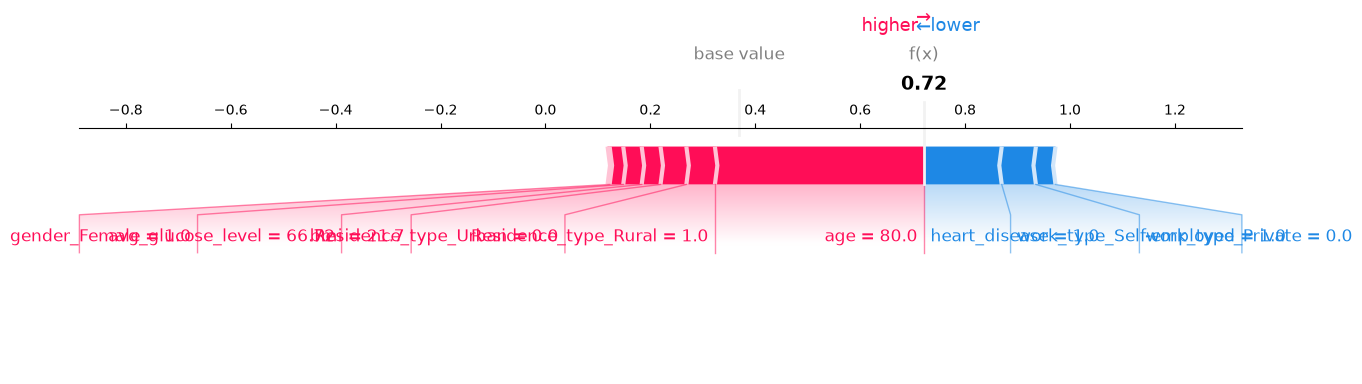

In [33]:
# Step 4: Local Kernel SHAP plot for Task 6 RBF SVM
# Display ORIGINAL patient values, even though SVM received scaled numeric inputs
shap.force_plot(
    svm_local_base, svm_local_values[0], X_local.iloc[0],
    feature_names=feature_names, matplotlib=True, show=False, figsize=(15, 3.2)
)

plt.savefig(OUT / "task6_kernel_local_force.png", dpi=220, bbox_inches="tight")
plt.show()



In [34]:
# Display all 21 local SVM Kernel SHAP feature contributions

# Use original numerical values and encoded categorical values
X_local_display = X_local_svm.copy()

for col in ["age", "avg_glucose_level", "bmi"]:
    X_local_display[col] = X_local[col].values

# Create feature contribution table
svm_local_contributions = pd.DataFrame({
    "Feature": feature_names,
    "Patient Value": X_local_display.iloc[0].values,
    "SHAP Value": svm_local_values[0]
})

# Add direction for stroke output
svm_local_contributions["Direction for Stroke Output"] = np.where(
    svm_local_contributions["SHAP Value"] > 0,
    "Increases",
    np.where(
        svm_local_contributions["SHAP Value"] < 0,
        "Decreases",
        "No effect"
    )
)

# Sort by absolute SHAP value (largest influence first)
svm_local_contributions = (
    svm_local_contributions
    .reindex(
        svm_local_contributions["SHAP Value"]
        .abs()
        .sort_values(ascending=False)
        .index
    )
    .reset_index(drop=True)
)

svm_local_contributions.index += 1
svm_local_contributions.index.name = "Rank"

print("=== All 21 Local SVM SHAP Feature Contributions ===")
display(svm_local_contributions)

=== All 21 Local SVM SHAP Feature Contributions ===


,Feature,Patient Value,SHAP Value,Direction for Stroke Output
Rank,,,,
1,age,80.00,0.398619,Increases
2,heart_disease,1.00,-0.148169,Decreases
3,work_type_Self-employed,1.00,-0.065126,Decreases
4,Residence_type_Rural,1.00,0.054405,Increases
5,Residence_type_Urban,0.00,0.049268,Increases
6,work_type_Private,0.00,-0.037378,Decreases
7,bmi,21.70,0.035889,Increases
8,avg_glucose_level,66.72,0.035170,Increases
9,gender_Female,1.00,0.025954,Increases


C:\Users\user\AppData\Local\Temp\ipykernel_2444\2614475394.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


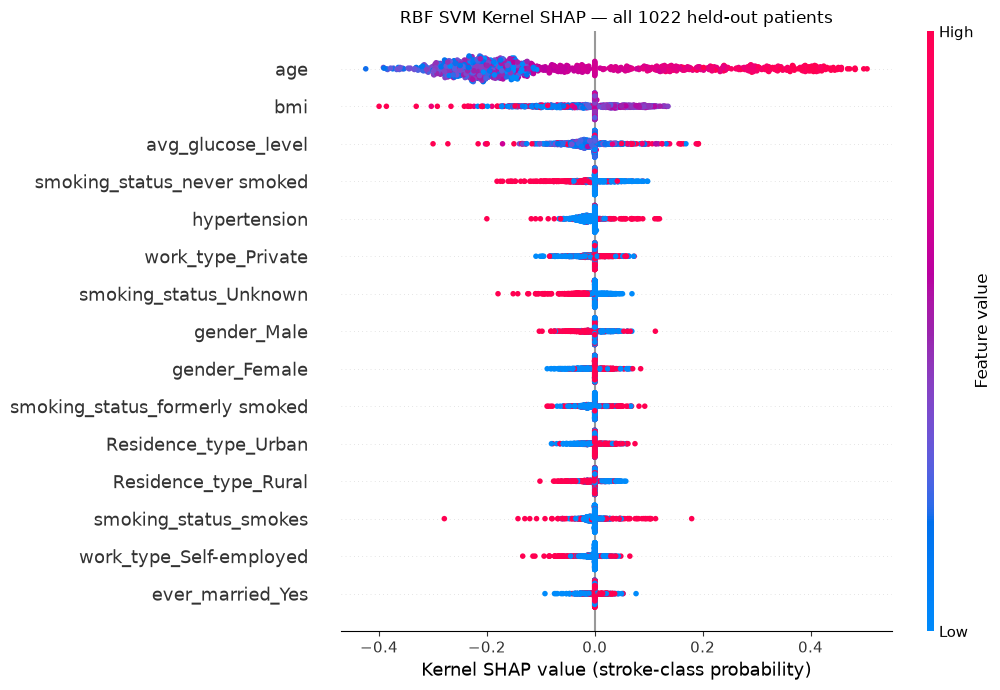

In [35]:
# Step 5: Global SVM Kernel SHAP beeswarm for ALL held-out test patients
# Original, unscaled values are used only for feature-colour/label display.
# Contributions were calculated using the correctly scaled SVM inputs.
shap.summary_plot(
    svm_global_values,
    X_task6_original,
    max_display=15,
    show=False
)
plt.gcf().set_size_inches(10.5, 7)
plt.title(f"RBF SVM Kernel SHAP — all {len(X_task6_svm)} held-out patients")
plt.xlabel("Kernel SHAP value (stroke-class probability)")
plt.tight_layout()
plt.savefig(OUT / "task6_kernel_global_beeswarm.png", dpi=220,
            bbox_inches="tight")
plt.show()

SVM global sample: 1022 held-out patients
Top five SVM features based on absolute Kernel SHAP:


,Rank,Feature,Mean Absolute SHAP
0,1,age,0.206937
1,2,bmi,0.052708
2,3,avg_glucose_level,0.029632
3,4,smoking_status_never smoked,0.021113
4,5,hypertension,0.015785


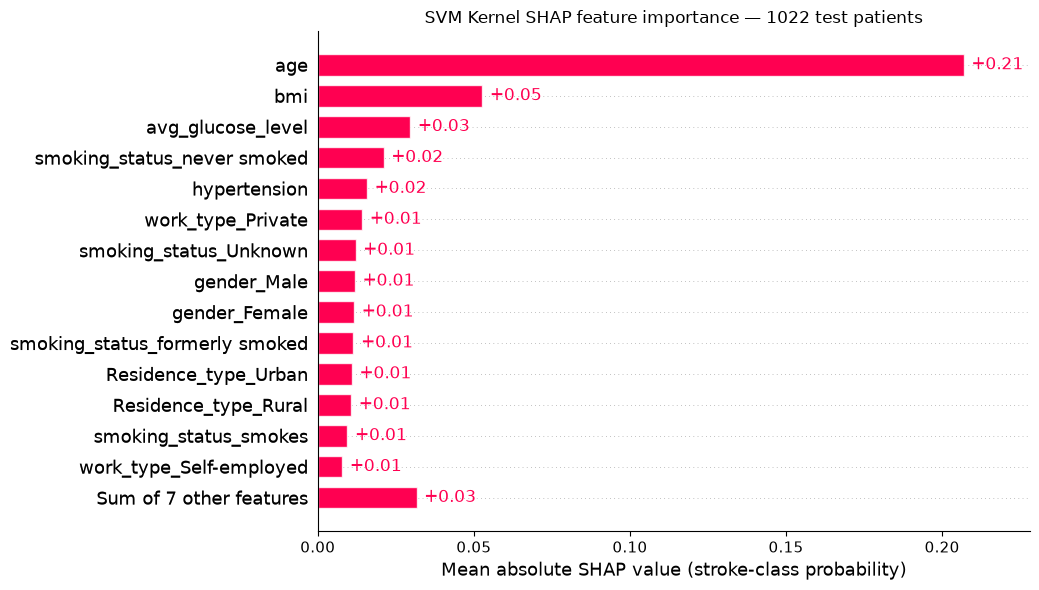

In [36]:
# Step 6: Mean absolute Kernel SHAP feature importance (ALL held-out patients)
svm_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(svm_global_values).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False).reset_index(drop=True)
svm_importance.insert(0, "Rank", np.arange(1, len(svm_importance) + 1))

print("SVM global sample:", len(X_task6_svm), "held-out patients")
print("Top five SVM features based on absolute Kernel SHAP:")
display(svm_importance.head(5))
svm_importance.to_csv(OUT / "task6_svm_feature_importance.csv", index=False)

svm_global_explanation = shap.Explanation(
    values=svm_global_values,
    data=X_task6_original.to_numpy(),
    feature_names=list(feature_names)
)
shap.plots.bar(svm_global_explanation, max_display=15, show=False)
plt.gcf().set_size_inches(10.5, 6)
plt.title(f"SVM Kernel SHAP feature importance — {len(X_task6_svm)} test patients")
plt.xlabel("Mean absolute SHAP value (stroke-class probability)")
plt.tight_layout()
plt.savefig(OUT / "task6_svm_shap_importance.png", dpi=220,
            bbox_inches="tight")
plt.show()

# Comparison Discussion

In [37]:
# Compare the two models: original Task 2-4 (RF) and Task 6 (SVM) results
# Both models have been evaluated and globally explained on the SAME 1,022
# held-out patients. Use the ACTUAL full-test SHAP results rather than
# recomputing a new 20-patient subset for the comparison.
rf_residual = abs(
    float(stroke_local[0].base_values + stroke_local[0].values.sum())
    - float(rf.predict_proba(X_local)[0, positive_index])
)

comparison = pd.DataFrame({
    "Item": [
        "Model / Explainer", "Accuracy", "Precision (stroke=1)",
        "Recall (stroke=1)", "F1 (stroke=1)", "Balanced Accuracy",
        "ROC AUC", "Average Precision", "Test Prevalence",
        "Same Patient Class-1 Probability", "Top Three Global Features",
        "Global Explanation Sample", "Local Explanation Sample",
        "SHAP Background", "Local SHAP Time (s)", "Global SHAP Time (s)",
        "Total SHAP Time (s)", "Local Reconstruction Residual"
    ],
    "Task 2 Random Forest": [
        "Random Forest / Tree SHAP",
        results["Accuracy"], results["Precision (stroke=1)"],
        results["Recall (stroke=1)"], results["F1-Score (stroke=1)"],
        results["Balanced Accuracy"], results["ROC AUC"],
        results["Average Precision"], float(y_test.mean()),
        float(rf.predict_proba(X_local)[0, positive_index]),
        ", ".join(importance.head(3)["Feature"]),
        f"{len(X_explain)} held-out test patients",
        f"1 patient: index {patient_index}",
        "Internal tree paths of oversampled training data",
        rf_local_runtime, rf_global_runtime, rf_total_runtime,
        rf_residual
    ],
    "Task 6 RBF SVM": [
        "RBF SVM / Kernel SHAP",
        svm_results["Accuracy"], svm_results["Precision (stroke=1)"],
        svm_results["Recall (stroke=1)"], svm_results["F1-Score (stroke=1)"],
        svm_results["Balanced Accuracy"], svm_results["ROC AUC"],
        svm_results["Average Precision"], float(y_test.mean()),
        svm_local_model,
        ", ".join(svm_importance.head(3)["Feature"]),
        f"{len(X_task6_svm)} held-out test patients",
        f"1 patient: index {patient_index}",
        f"{len(background_svm)} original training rows, seed {SEED}",
        svm_local_runtime, svm_global_runtime, svm_kernel_runtime,
        svm_residual
    ]
})

display(comparison)
comparison.to_csv(OUT / "task6_model_comparison.csv", index=False)
print("Comparison saved:", (OUT / "task6_model_comparison.csv").resolve())
print("Note: Tree SHAP and Kernel SHAP use different reference backgrounds;")
print("their feature attributions should not be treated as causal effects.")

,Item,Task 2 Random Forest,Task 6 RBF SVM
0,Model / Explainer,Random Forest / Tree SHAP,RBF SVM / Kernel SHAP
1,Accuracy,0.940313,0.76908
2,Precision (stroke=1),0.210526,0.115702
3,Recall (stroke=1),0.08,0.56
4,F1 (stroke=1),0.115942,0.191781
5,Balanced Accuracy,0.532284,0.669918
6,ROC AUC,0.768745,0.782407
7,Average Precision,0.12959,0.166627
8,Test Prevalence,0.048924,0.048924
9,Same Patient Class-1 Probability,0.18,0.721685


Comparison saved: C:\Users\user\OneDrive\0. Master Degree\1. Sem 1 2026_2027\Assignment\XAI\Stroke_Prediction\output\task6_model_comparison.csv
Note: Tree SHAP and Kernel SHAP use different reference backgrounds;
their feature attributions should not be treated as causal effects.


## Task 6 / Section 8.2 — Background-sample stability check

**Three distinct training backgrounds.** For each seed (21, 42 and 123), sample 1,022 different records from the original 4,088-row training pool, without replacement and stratified by stroke class. Random Forest and RBF SVM use the same patient IDs as their background, with each model using its appropriate feature scaling. The three backgrounds differ across seeds. Interventional Tree SHAP explicitly uses all 1,022 rows with an Independent masker; Kernel SHAP also uses all 1,022 background rows.

To limit runtime, Section 8.2 explains a fixed, shared sample of 100 held-out test patients, including the local patient (index 75), instead of repeating global SHAP for all 1,022 test patients. The original Task 4 and Task 6 global results for all 1,022 test patients remain unchanged. Kernel SHAP uses nsamples=32, which is faster but may introduce additional attribution variability; report only observed results and check reconstruction residuals. The seed-21 stability background is not identical to the original Task 6 seed-21 30-row background.

In [38]:
# Step 19: Stability settings: three different 1,022-record TRAINING backgrounds
# Each background is a stratified subset of the original 4,088-record training pool.
# Local and global stability explanations use the SAME held-out cases across seeds.
# The main Task 4 / Task 6 full-test (1,022-case) explanations remain unchanged.
from pathlib import Path
from sklearn.model_selection import train_test_split
from joblib import hash as joblib_hash
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

STABILITY_SEEDS = (21, 42, 123)
STABILITY_BACKGROUND_N = 1022 # Different 1,022-record TRAINING backgrounds, NOT test data.
STABILITY_TEST_N = 100        # Only Section 8.2 stability; None = all 1,022 test cases.
STABILITY_TEST_SEED = 42       # Fixed, shared subset across the three backgrounds.
STABILITY_NSAMPLES = 32      # Faster than 96; approximate SHAP, verify ranking stability.
STABILITY_L1 = "num_features(10)"
STABILITY_ZERO_TOL = 1e-4     # Ignore tiny, unstable SHAP signs.
RF_STABILITY_BATCH_SIZE = 20
SVM_STABILITY_BATCH_SIZE = 10

STABILITY_OUT = OUT / "background_stability_1022_train_100_test_21_42_123"
STABILITY_OUT.mkdir(parents=True, exist_ok=True)

rf_training = X_train.loc[:, feature_names].copy()
svm_training = X_train_svm.loc[:, feature_names].copy()
assert rf_training.index.equals(svm_training.index)
assert rf_training.index.equals(y_train.index)
assert rf_training.index.is_unique

rf_full_test = X_test.loc[:, feature_names]
svm_full_test = X_test_svm.loc[:, feature_names]
assert rf_full_test.index.equals(svm_full_test.index)
assert rf_full_test.index.equals(y_test.index)
assert patient_index in rf_full_test.index

if STABILITY_TEST_N is None or STABILITY_TEST_N >= len(rf_full_test):
    selected_test_index = rf_full_test.index
else:
    if not 3 <= STABILITY_TEST_N < len(rf_full_test):
        raise ValueError("STABILITY_TEST_N must be >=3 or None.")
    # Stratified approximate mix from remaining test cases; always include
    # the selected local patient for comparable local explanations.
    other_labels = y_test.drop(index=patient_index)
    chosen_other, _ = train_test_split(
        other_labels.index.to_numpy(),
        train_size=STABILITY_TEST_N - 1,
        stratify=other_labels.to_numpy(),
        random_state=STABILITY_TEST_SEED,
    )
    selected_ids = set(chosen_other)
    selected_ids.add(patient_index)
    selected_test_index = rf_full_test.index[
        rf_full_test.index.isin(selected_ids)
    ]

rf_stability_test = rf_full_test.loc[selected_test_index].copy()
svm_stability_test = svm_full_test.loc[selected_test_index].copy()
assert len(rf_stability_test) == len(svm_stability_test)
assert patient_index in rf_stability_test.index
assert rf_stability_test.index.equals(svm_stability_test.index)

# Draw 1,022 DISTINCT training rows per seed, with class stratification.
# Sampled row IDs differ across seeds, while both models receive the SAME IDs.
# These seed-21 rows are NOT the original Task 6 30-record baseline background:
# the old and new experiments use different sample sizes.
stability_draws = {}
for seed in STABILITY_SEEDS:
    chosen, _ = train_test_split(
        rf_training.index.to_numpy(),
        train_size=min(STABILITY_BACKGROUND_N, len(rf_training)-1),
        random_state=seed,
        stratify=y_train.loc[rf_training.index].to_numpy(),
    )
    stability_draws[seed] = pd.Index(chosen)

stability_backgrounds = {
    seed: {
        "rf": rf_training.loc[indices].reset_index(drop=True),
        "svm": svm_training.loc[indices].reset_index(drop=True),
    }
    for seed, indices in stability_draws.items()
}

for a, seed_a in enumerate(STABILITY_SEEDS):
    for seed_b in STABILITY_SEEDS[a+1:]:
        assert set(stability_draws[seed_a]) != set(stability_draws[seed_b]), (
            f"Backgrounds {seed_a} and {seed_b} were identical"
        )

assert all(len(v["svm"]) == STABILITY_BACKGROUND_N
           for v in stability_backgrounds.values())
assert all(len(v["rf"]) == STABILITY_BACKGROUND_N
           for v in stability_backgrounds.values())

print("Different background row counts by seed:",
      {s: len(stability_draws[s]) for s in STABILITY_SEEDS})
print("Stroke-positive background counts by seed:",
      {s: int(y_train.loc[stability_draws[s]].sum()) for s in STABILITY_SEEDS})


def stability_direction(values, eps=STABILITY_ZERO_TOL):
    values = np.asarray(values, dtype=float)
    return np.where(values > eps, "Increases",
                    np.where(values < -eps, "Decreases", "Near zero"))


def stability_cache_key(model, background, cases, *, model_name, seed):
    h = hashlib.sha256()
    config = (
        joblib_hash(model), shap.__version__, model_name, str(seed),
        str(STABILITY_BACKGROUND_N), str(STABILITY_TEST_N),
        str(STABILITY_TEST_SEED), str(STABILITY_NSAMPLES),
        str(STABILITY_L1), str(SVM_STABILITY_BATCH_SIZE),
        "stratified_without_replacement", "identity", "|".join(feature_names)
    )
    h.update("::".join(config).encode("utf-8"))
    for frame in (background, cases):
        h.update(np.asarray(frame.to_numpy(), dtype=np.float64).tobytes())
        h.update(str(tuple(frame.index)).encode("utf-8"))
    return h.hexdigest()[:20]


def save_stability_batch(path, values, elapsed):
    temp = path.with_suffix(".tmp.npz")
    np.savez_compressed(temp, values=np.asarray(values, dtype=float),
                        elapsed=float(elapsed))
    temp.replace(path)


def load_stability_batch(path, expected_shape):
    if not path.is_file():
        return None
    with np.load(path, allow_pickle=False) as loaded:
        vals = np.asarray(loaded["values"], dtype=float)
        elapsed = float(loaded["elapsed"])
    if vals.shape != expected_shape:
        raise ValueError(f"Wrong cached SHAP shape in {path}: {vals.shape}")
    return vals, elapsed


def top_features(shap_matrix, n):
    scores = np.mean(np.abs(np.asarray(shap_matrix, dtype=float)), axis=0)
    return [feature_names[int(i)] for i in np.argsort(-scores)[:n]]

print("Training pool:", len(rf_training), "original patients")
print("Different backgrounds:", STABILITY_SEEDS,
      "|", len(stability_backgrounds[21]["svm"]), "records each")
print("Stability test patients per run:", len(selected_test_index),
      "| stroke-positive:", int(y_test.loc[selected_test_index].sum()),
      "| local index:", patient_index)


Different background row counts by seed: {21: 1022, 42: 1022, 123: 1022}
Stroke-positive background counts by seed: {21: 50, 42: 50, 123: 50}
Training pool: 4088 original patients
Different backgrounds: (21, 42, 123) | 1022 records each
Stability test patients per run: 100 | stroke-positive: 6 | local index: 75


In [39]:
# Step 20: RF interventional Tree SHAP, 3 different 1,022-record training backgrounds
rf_stability_runs = {}
rf_probs = rf.predict_proba(rf_stability_test)[:, positive_index]
local_position = rf_stability_test.index.get_loc(patient_index)

for seed in STABILITY_SEEDS:
    background = stability_backgrounds[seed]["rf"]
    # By default SHAP Independent only retains 100 background rows.
    # Set max_samples explicitly so all 1,022 sampled training rows are used.
    rf_masker = shap.maskers.Independent(
        background, max_samples=len(background)
    )
    explainer_seed = shap.TreeExplainer(
        rf, data=rf_masker,
        model_output="probability",
        feature_perturbation="interventional"
    )
    ev = np.asarray(explainer_seed.expected_value, dtype=float).reshape(-1)
    baseline = float(ev[positive_index])
    signature = stability_cache_key(
        rf, background, rf_stability_test,
        model_name="rf_interventional_fast", seed=seed
    )
    cache_dir = STABILITY_OUT / f"rf_seed_{seed}" / signature
    cache_dir.mkdir(parents=True, exist_ok=True)
    parts, times = [], []

    for start in range(0, len(rf_stability_test), RF_STABILITY_BATCH_SIZE):
        stop = min(start + RF_STABILITY_BATCH_SIZE, len(rf_stability_test))
        path = cache_dir / f"rf_{start:04d}_{stop:04d}.npz"
        cached = load_stability_batch(path, (stop-start, len(feature_names)))
        if cached is None:
            tick = time.perf_counter()
            explained = explainer_seed(
                rf_stability_test.iloc[start:stop], check_additivity=False
            )
            vals = np.asarray(explained.values)
            if vals.ndim == 3:
                vals = vals[..., positive_index]
            if vals.shape != (stop-start, len(feature_names)):
                raise ValueError(f"Unexpected RF SHAP shape: {vals.shape}")
            elapsed = time.perf_counter() - tick
            save_stability_batch(path, vals, elapsed)
        else:
            vals, elapsed = cached
        parts.append(vals)
        times.append(elapsed)
        print(f"RF seed {seed}: {stop}/{len(rf_stability_test)} cases ready", end="\r")
    print()

    values = np.vstack(parts)
    residuals = np.abs(baseline + values.sum(axis=1) - rf_probs)
    rf_stability_runs[seed] = {
        "global": values,
        "local": values[local_position].copy(),
        "base": baseline,
        "max_residual": float(residuals.max()),
        "runtime": float(sum(times)),
    }
    print(f"RF seed {seed} | top 3: {', '.join(top_features(values, 3))}"
          f" | max residual: {residuals.max():.7f} | run time: {sum(times):.1f}s")
    if residuals.max() > 1e-4:
        print("WARNING: RF additivity residual >1e-4; interpret with caution.")


RF seed 21: 100/100 cases ready
RF seed 21 | top 3: age, avg_glucose_level, bmi | max residual: 0.0000391 | run time: 21.4s
RF seed 42: 100/100 cases ready
RF seed 42 | top 3: age, avg_glucose_level, bmi | max residual: 0.0000294 | run time: 21.3s
RF seed 123: 100/100 cases ready
RF seed 123 | top 3: age, avg_glucose_level, bmi | max residual: 0.0000098 | run time: 21.2s


In [40]:
# Step 21: SVM Kernel SHAP, 3 different 1,022-record training backgrounds
# Explain the SHARED 100-test-case stability subset (not the full 1,022 test cases).
# Checkpoints allow interrupted batches to resume, including across restarts.
svm_stability_runs = {}
svm_probs = svm_stroke_probability(svm_stability_test)
svm_local_position = svm_stability_test.index.get_loc(patient_index)

for seed in STABILITY_SEEDS:
    background = stability_backgrounds[seed]["svm"]
    # KernelExplainer uses all 1,022 background rows. Unlike Tree SHAP,
    # this remains computationally heavy; lower STABILITY_TEST_N if required.
    kernel_seed = shap.KernelExplainer(
        svm_stroke_probability, background, link="identity"
    )
    baseline = float(kernel_seed.expected_value)
    signature = stability_cache_key(
        svm, background, svm_stability_test,
        model_name="svm_kernel_fast", seed=seed
    )
    cache_dir = STABILITY_OUT / f"svm_seed_{seed}" / signature
    cache_dir.mkdir(parents=True, exist_ok=True)
    parts, times = [], []

    for start in range(0, len(svm_stability_test), SVM_STABILITY_BATCH_SIZE):
        stop = min(start + SVM_STABILITY_BATCH_SIZE, len(svm_stability_test))
        path = cache_dir / f"svm_{start:04d}_{stop:04d}.npz"
        cached = load_stability_batch(path, (stop-start, len(feature_names)))
        if cached is None:
            np.random.seed(seed + start)
            tick = time.perf_counter()
            vals = as_svm_shap_2d(
                kernel_seed.shap_values(
                    svm_stability_test.iloc[start:stop],
                    nsamples=STABILITY_NSAMPLES,
                    l1_reg=STABILITY_L1, silent=True
                ), stop-start
            )
            elapsed = time.perf_counter() - tick
            save_stability_batch(path, vals, elapsed)
        else:
            vals, elapsed = cached
        parts.append(vals)
        times.append(elapsed)
        print(f"SVM seed {seed}: {stop}/{len(svm_stability_test)} cases ready", end="\r")
    print()

    values = np.vstack(parts)
    residuals = np.abs(baseline + values.sum(axis=1) - svm_probs)
    svm_stability_runs[seed] = {
        "global": values,
        "local": values[svm_local_position].copy(),
        "base": baseline,
        "max_residual": float(residuals.max()),
        "runtime": float(sum(times)),
    }
    print(f"SVM seed {seed} | top 3: {', '.join(top_features(values, 3))}"
          f" | max residual: {residuals.max():.7f} | run time: {sum(times):.1f}s")
    if residuals.max() > 1e-4:
        print("WARNING: SVM additivity residual >1e-4; interpret with caution.")


Using 1022 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=6.171e-04, with an active set of 5 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=4.004e-04, with an active set of 8 regressors, and the smallest cholesky pivot element being 2.980e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=3.232e-04, with an active set of 6 regressors, and the smallest cholesky pivot element being 5.162e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=2.228e-04, with an active set of 8 regressors, and the smallest cholesky pivot element being 5.162e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 1 iterations, i.e. alpha=4.396e-03, with an active set of 1 regressors, and the smallest cholesky pivot element b

c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=1.460e-04, with an active set of 9 regressors, and the smallest cholesky pivot element being 2.980e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=5.738e-04, with an active set of 5 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 7 iterations, i.e. alpha=2.869e-04, with an active set of 7 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(


c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 3 iterations, i.e. alpha=8.410e-04, with an active set of 3 regressors, and the smallest cholesky pivot element being 3.650e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=5.398e-04, with an active set of 6 regressors, and the smallest cholesky pivot element being 3.650e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=5.398e-04, with an active set of 6 regressors, and the smallest cholesky pivot element b

c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 7 iterations, i.e. alpha=1.448e-03, with an active set of 7 regressors, and the smallest cholesky pivot element being 4.215e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=4.103e-04, with an active set of 8 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(


... (18 outputs left out)

c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=7.427e-04, with an active set of 8 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=4.440e-04, with an active set of 9 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 9 iterations, i.e. alpha=4.443e-04, with an active set of 9 regressors, and the smallest cholesky pivot element b

c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=9.059e-04, with an active set of 5 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 2 iterations, i.e. alpha=4.363e-03, with an active set of 2 regressors, and the smallest cholesky pivot element being 2.980e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=1.475e-03, with an active set of 7 regressors, and the smallest cholesky pivot element b

c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 5 iterations, i.e. alpha=2.790e-03, with an active set of 5 regressors, and the smallest cholesky pivot element being 4.215e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\user\anaconda3\Lib\site-packages\sklearn\linear_model\_least_angle.py:727: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 4 iterations, i.e. alpha=1.375e-04, with an active set of 4 regressors, and the smallest cholesky pivot element being 4.215e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(


SVM seed 123: 100/100 cases ready
SVM seed 123 | top 3: age, bmi, avg_glucose_level | max residual: 0.0000000 | run time: 541.9s



=== Random Forest (interventional Tree SHAP) ===
Seed 21: top 3 global features: age, avg_glucose_level, bmi; max reconstruction residual: 0.00003914. Runtime: 21.4s.
Seed 42: top 3 global features: age, avg_glucose_level, bmi; max reconstruction residual: 0.00002936. Runtime: 21.3s.
Seed 123: top 3 global features: age, avg_glucose_level, bmi; max reconstruction residual: 0.00000979. Runtime: 21.2s.
Seed 21 versus seed 42: 5/5 top features in common; 0 meaningful local sign reversals (none).
Seed 21 versus seed 123: 5/5 top features in common; 0 meaningful local sign reversals (none).


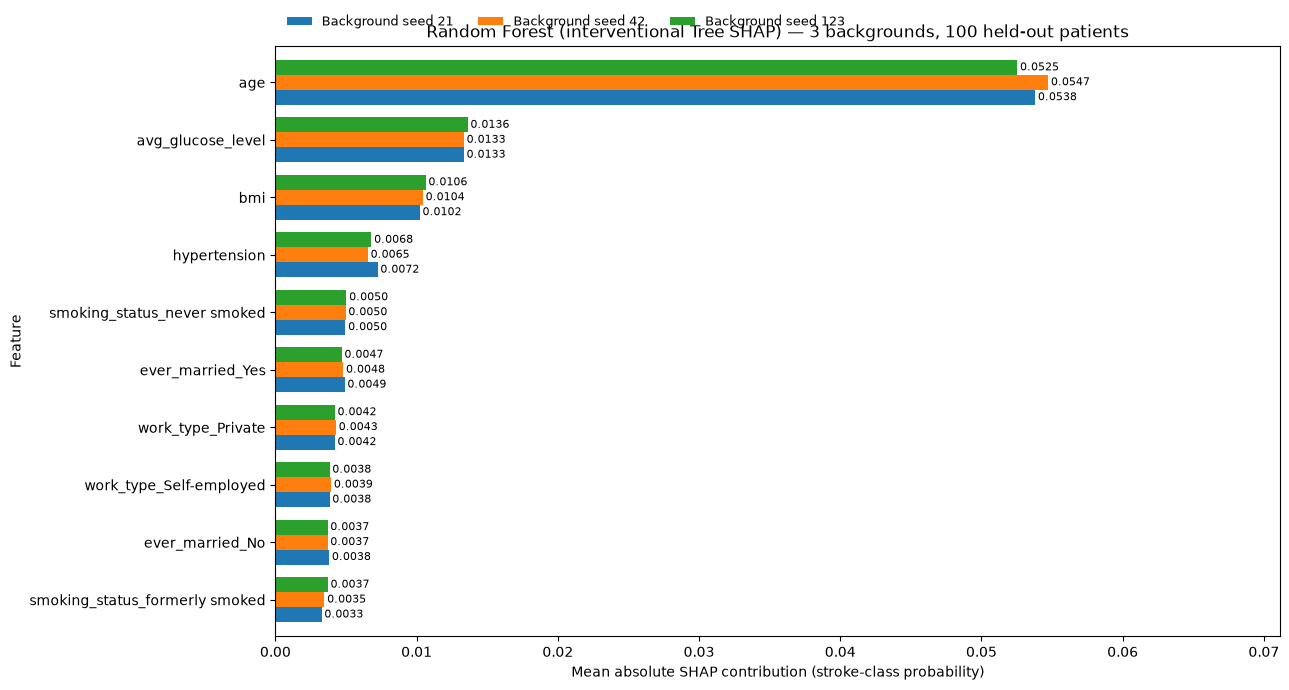

,Feature,Background seed 21,Background seed 42,Background seed 123
0,age,0.053802,0.054724,0.052536
1,avg_glucose_level,0.013340,0.013345,0.013614
2,bmi,0.010220,0.010443,0.010640
19,hypertension,0.007236,0.006547,0.006795
17,smoking_status_never smoked,0.004956,0.004970,0.005027
7,ever_married_Yes,0.004902,0.004805,0.004691
10,work_type_Private,0.004199,0.004287,0.004202
11,work_type_Self-employed,0.003832,0.003943,0.003832
6,ever_married_No,0.003806,0.003691,0.003692
16,smoking_status_formerly smoked,0.003269,0.003469,0.003709


,Feature,SHAP seed 21,Direction seed 21,SHAP seed 42,Direction seed 42,SHAP seed 123,Direction seed 123,Opposite signs vs seed 21 — seed 42,Opposite signs vs seed 21 — seed 123
0,age,0.127358,Increases,0.127864,Increases,0.128292,Increases,False,False
1,avg_glucose_level,0.004758,Increases,0.005383,Increases,0.003557,Increases,False,False
2,bmi,-0.015395,Decreases,-0.015743,Decreases,-0.015893,Decreases,False,False
3,gender_Female,0.002358,Increases,0.002207,Increases,0.002562,Increases,False,False
4,gender_Male,0.001355,Increases,0.001364,Increases,0.001631,Increases,False,False
5,gender_Other,0.000000,Near zero,0.000000,Near zero,0.000000,Near zero,False,False
6,ever_married_No,-0.000810,Decreases,-0.000904,Decreases,-0.000525,Decreases,False,False
7,ever_married_Yes,-0.001343,Decreases,-0.001382,Decreases,-0.001104,Decreases,False,False
8,work_type_Govt_job,0.001007,Increases,0.000888,Increases,0.001011,Increases,False,False
9,work_type_Never_worked,0.000005,Near zero,0.000005,Near zero,0.000001,Near zero,False,False



=== RBF SVM (Kernel SHAP) ===
Seed 21: top 3 global features: age, bmi, avg_glucose_level; max reconstruction residual: 0.00000000. Runtime: 536.3s.
Seed 42: top 3 global features: age, bmi, avg_glucose_level; max reconstruction residual: 0.00000000. Runtime: 547.8s.
Seed 123: top 3 global features: age, bmi, avg_glucose_level; max reconstruction residual: 0.00000000. Runtime: 541.9s.
Seed 21 versus seed 42: 4/5 top features in common; 0 meaningful local sign reversals (none).
Seed 21 versus seed 123: 5/5 top features in common; 1 meaningful local sign reversals (smoking_status_Unknown).


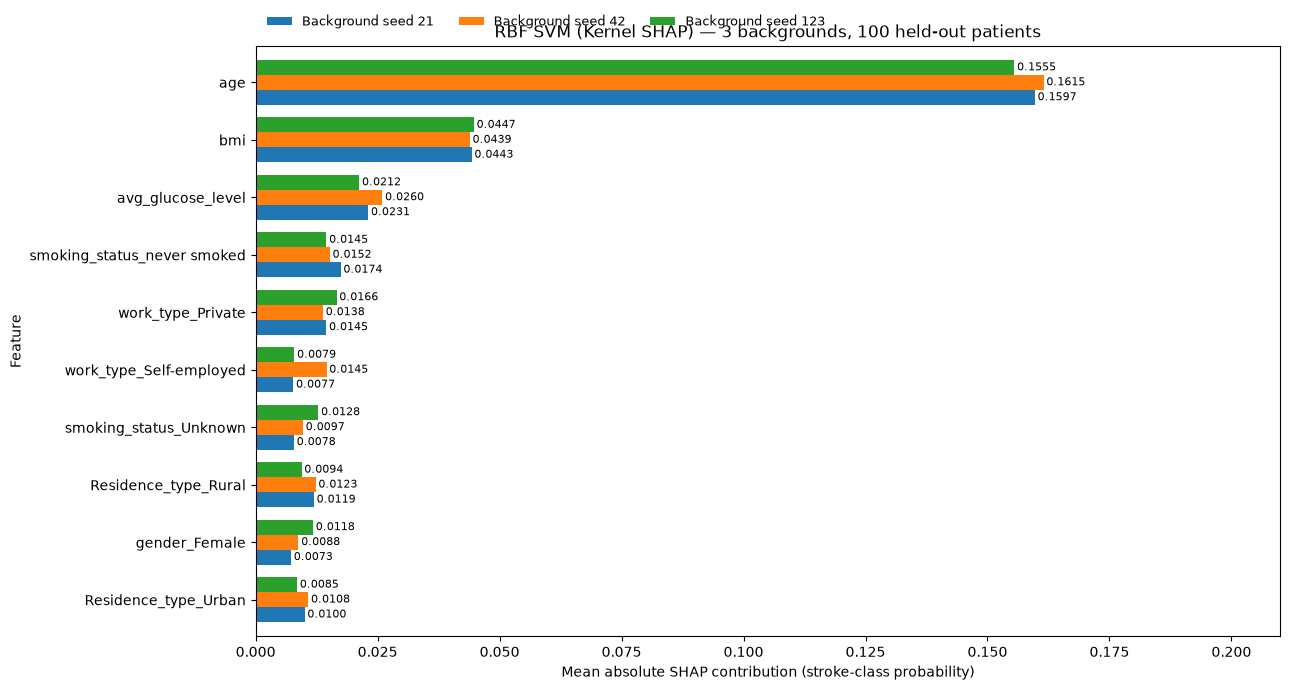

,Feature,Background seed 21,Background seed 42,Background seed 123
0,age,0.159709,0.161504,0.155506
2,bmi,0.044267,0.043895,0.044727
1,avg_glucose_level,0.023070,0.025963,0.021237
17,smoking_status_never smoked,0.017421,0.015194,0.014493
10,work_type_Private,0.014475,0.013794,0.016574
11,work_type_Self-employed,0.007716,0.014521,0.007925
15,smoking_status_Unknown,0.007849,0.009691,0.012843
13,Residence_type_Rural,0.011930,0.012291,0.009401
3,gender_Female,0.007252,0.008770,0.011758
14,Residence_type_Urban,0.010028,0.010785,0.008488


,Feature,SHAP seed 21,Direction seed 21,SHAP seed 42,Direction seed 42,SHAP seed 123,Direction seed 123,Opposite signs vs seed 21 — seed 42,Opposite signs vs seed 21 — seed 123
0,age,0.419984,Increases,0.446193,Increases,0.482467,Increases,False,False
1,avg_glucose_level,0.047259,Increases,0.167773,Increases,0.000000,Near zero,False,False
2,bmi,0.095905,Increases,0.039110,Increases,0.088546,Increases,False,False
3,gender_Female,0.000000,Near zero,-0.246212,Decreases,0.063683,Increases,False,False
4,gender_Male,0.000000,Near zero,0.000000,Near zero,0.000000,Near zero,False,False
5,gender_Other,0.000000,Near zero,0.000000,Near zero,0.000000,Near zero,False,False
6,ever_married_No,0.000000,Near zero,0.000000,Near zero,-0.107285,Decreases,False,False
7,ever_married_Yes,0.041704,Increases,0.000000,Near zero,0.000000,Near zero,False,False
8,work_type_Govt_job,0.000000,Near zero,0.004487,Increases,0.000000,Near zero,False,False
9,work_type_Never_worked,0.000000,Near zero,-0.017605,Decreases,0.000000,Near zero,False,False



8.2 Background stability — observed results (1,022-row backgrounds)

Original training pool: 4,088 non-oversampled records.
Three DISTINCT stratified 1022-record training backgrounds sampled WITHOUT replacement using seeds 21, 42 and 123.
Same 100 held-out patients for each explanation; local patient index 75.
Kernel SHAP: nsamples=32; l1_reg=num_features(10).
Main Task 4 and Task 6 SHAP results cover all 1,022 test patients; the smaller Section 8.2 subset is used only for this stability check.

Random Forest (interventional Tree SHAP):
Seed 21: top 3 global features: age, avg_glucose_level, bmi; max reconstruction residual: 0.00003914. Runtime: 21.4s.
Seed 42: top 3 global features: age, avg_glucose_level, bmi; max reconstruction residual: 0.00002936. Runtime: 21.3s.
Seed 123: top 3 global features: age, avg_glucose_level, bmi; max reconstruction residual: 0.00000979. Runtime: 21.2s.
Seed 21 versus seed 42: 5/5 top features in common; 0 meaningful local sign reversals (none).
Seed 21

In [41]:
# Step 22: FAST stability comparison — observed results, not assumed results
# All 3 seeds use the SAME 100 cases (or STABILITY_TEST_N selected amount).
comparison_sets = [
    ("Random Forest (interventional Tree SHAP)", "rf", rf_stability_runs),
    ("RBF SVM (Kernel SHAP)", "svm", svm_stability_runs),
]

report_lines = [
    "8.2 Background stability — observed results (1,022-row backgrounds)",
    "",
    f"Original training pool: {len(rf_training):,} non-oversampled records.",
    f"Three DISTINCT stratified {STABILITY_BACKGROUND_N}-record training backgrounds sampled WITHOUT replacement using seeds 21, 42 and 123.",
    f"Same {len(rf_stability_test)} held-out patients for each explanation; local patient index {patient_index}.",
    f"Kernel SHAP: nsamples={STABILITY_NSAMPLES}; l1_reg={STABILITY_L1}.",
    "Main Task 4 and Task 6 SHAP results cover all 1,022 test patients; the smaller Section 8.2 subset is used only for this stability check.",
    "",
]

for model_title, stem, runs in comparison_sets:
    assert set(runs) == set(STABILITY_SEEDS), f"Missing {stem} runs"
    print(f"\n=== {model_title} ===")
    report_lines.append(model_title + ":")
    global_tab = pd.DataFrame({"Feature": feature_names})
    local_tab = pd.DataFrame({"Feature": feature_names})
    importance_cols = []

    for seed in STABILITY_SEEDS:
        col = f"Background seed {seed}"
        importance_cols.append(col)
        vals = np.asarray(runs[seed]["global"], dtype=float)
        loc = np.asarray(runs[seed]["local"], dtype=float)
        assert vals.shape == (len(rf_stability_test), len(feature_names))
        assert loc.shape == (len(feature_names),)
        global_tab[col] = np.abs(vals).mean(axis=0)
        global_tab[f"Rank seed {seed}"] = global_tab[col].rank(
            ascending=False, method="first").astype(int)
        local_tab[f"SHAP seed {seed}"] = loc
        local_tab[f"Direction seed {seed}"] = stability_direction(loc)
        line = (f"Seed {seed}: top 3 global features: "
                + ", ".join(top_features(vals, 3))
                + f"; max reconstruction residual: {runs[seed]['max_residual']:.8f}."
                + f" Runtime: {runs[seed]['runtime']:.1f}s.")
        print(line)
        report_lines.append(line)

    baseline_signs = stability_direction(runs[21]["local"])
    base_top_five = set(top_features(runs[21]["global"], 5))
    for seed in (42, 123):
        current_signs = stability_direction(runs[seed]["local"])
        reverse = (((baseline_signs == "Increases") & (current_signs == "Decreases")) |
                   ((baseline_signs == "Decreases") & (current_signs == "Increases")))
        local_tab[f"Opposite signs vs seed 21 — seed {seed}"] = reverse
        changed = [feature_names[i] for i in np.flatnonzero(reverse)]
        overlap = len(base_top_five & set(top_features(runs[seed]["global"], 5)))
        line = (f"Seed 21 versus seed {seed}: {overlap}/5 top features in common; "
                f"{len(changed)} meaningful local sign reversals "
                f"({', '.join(changed) if changed else 'none'}).")
        print(line)
        report_lines.append(line)
    report_lines.append("")

    global_tab["Max importance"] = global_tab[importance_cols].max(axis=1)
    global_tab.sort_values("Max importance", ascending=False, inplace=True)
    global_tab.to_csv(STABILITY_OUT / f"{stem}_three_backgrounds_global.csv", index=False)
    local_tab.to_csv(STABILITY_OUT / f"{stem}_three_backgrounds_local.csv", index=False)

    plot_data = global_tab.head(10).sort_values("Max importance")
    fig, ax = plt.subplots(figsize=(13, 7))
    plot_data.set_index("Feature")[importance_cols].plot.barh(ax=ax, width=0.78)
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.4f", padding=2, fontsize=8)
    peak = float(plot_data[importance_cols].to_numpy().max())
    ax.set_xlim(0, max(1e-4, peak*1.3))
    ax.set_title(model_title + f" — 3 backgrounds, {len(rf_stability_test)} held-out patients")
    ax.set_xlabel("Mean absolute SHAP contribution (stroke-class probability)")
    ax.set_ylabel("Feature")
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=3,
              frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(STABILITY_OUT / f"{stem}_three_backgrounds_comparison.png",
                dpi=220, bbox_inches="tight")
    plt.show()
    display(global_tab[["Feature"] + importance_cols].head(10))
    display(local_tab)

report_lines += [
    "Methodological note: Each seed uses 1,022 DIFFERENT training records sampled from the same 4,088-row pool.",
    "The seed-21 stability background is 1,022 rows, not the original Task 6 30-row reference sample.",
    "The comparison keeps the trained models and test cases fixed; changes in SHAP contributions",
    "may reflect the background sample and, for Kernel SHAP, approximation randomness.",
    "The original Random Forest tree-path explanation uses a different background method",
    "from the three interventional RF runs here. Compare the 3 interventional runs with each other.",
    "Do not report the stability subset results as though they covered all 1,022 test patients.",
    "Kernel SHAP nsamples=32 prioritises speed; compare trends cautiously because approximation noise may affect rankings.",
    "Check residuals, especially for Random Forest, before interpreting stability findings.",
]
final_stability_report = "\n".join(report_lines) + "\n"
print("\n" + final_stability_report)
(STABILITY_OUT / "section_8_2_three_backgrounds_1022_training.txt").write_text(
    final_stability_report, encoding="utf-8"
)
print("Saved fast stability analysis to:", STABILITY_OUT.resolve())
